# How tuning sharpens a code model's algorithm choice: a CPU replay of `method.py`

**The question.** When a code model writes a program, a single token often decides which algorithm it writes. For a
minimum spanning tree, Qwen3-8B picks ` Kr` (Kruskal) or ` Prim`. For grid path search, Gemma-3-4b picks between a
`visited`-first opening and BFS-style alternatives. This decision token is the **fork**. The experiment asks whether
instruction tuning makes a model commit to one answer at the fork, that is, whether it "gives the mean answer". It asks
three things:

* **B1 (behavioural).** On identical token ids, how much sharper is the instruct model than its base model at the fork,
  and is the base-vs-instruct divergence special to forks once the base model's entropy is controlled? (Gemma-3-4b
  pt/it, Llama-3.1-8B base/instruct, teacher forcing.)
* **B2 (mechanistic).** Which components of Qwen3-8B carry the sharpening? This is tested with **cross-model activation
  patching**: the outputs of chosen components of Qwen3-8B-Base are patched into the instruct run at the fork. The
  10-node fork stack (FSTACK) is compared against an exhaustive single-component sweep, 50 write-norm-matched random
  sets, the task-specification nodes and residual-stream swaps. A generation test then asks whether a one-token
  intervention changes the program the model writes.
* **B3.** A rerun of iteration 8's held-out validation of the layer-0 condition MLP, whose held-out arm never applied
  an edit because of a `MeanCache` bug.

**What `method.py` is.** A stage runner. Each stage runs one script from `src/` in its own process. The GPU stages
need six 4-8B models (about 65 GB of weights) and took about one GPU-hour on an NVIDIA L4. Every rule and prediction
was committed in a SHA-256 commitment chain before the decisive passes.

**What this notebook does.** It replays the **CPU side** of `method.py` on the outputs that the GPU stages recorded.
Those outputs are bundled in `mini_demo_data.json`. The replayed stages are `analyze` (B1, B3, B2), the analysis step
of `generate`, `figures` and `rederive`. Their functions are copied unchanged from `src/`. Lines that had to change are
marked `# [notebook]` (paths, imports, the stage dispatcher) or `# [replay]` (an input that only the GPU or an
unpublished cache could provide; the recorded value stands in). The whole notebook runs in under a minute on a CPU.

**Scope of the bundled data.** For B2 and B3, all recorded rows are included. For B1, only the unit **G-GRID** (grid
path search, BFS vs DFS) is included, with all 20 of its prompts and phrasing programs; the other B1 units add about
45 MB of top-256 log-probability rows. The base-model activation caches (about 12 GB) are not published, so figure F8
and the readout decomposition use their recorded results. The last cell adds a geometry view built from the
block-30 activation vectors that were published.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab, always install (method.py and every src/ module log through it)
_pip('loguru==0.7.3')

# numpy, matplotlib: pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# ---------------- imports of the replayed src/ modules (cfg9, stats9, b1_9, b3_9, analysis9, b2gen9, figures9,
# rederive9) and of the vendored k3motif.py
import hashlib
import itertools
import json
import math
import os
import random
import resource
import statistics
from datetime import datetime, timezone
from typing import Any, Iterable, Sequence

import numpy as np

import matplotlib
# matplotlib.use("Agg")   [notebook] figures9.py rendered off-screen; the notebook keeps its inline backend
import matplotlib.pyplot as plt  # noqa: E402
# import torch            [notebook] only the GPU stages, F8 and the CPU readout decomposition use torch

# ---------------- notebook helpers
import base64
import shutil
from types import SimpleNamespace

from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-9/experiment-50/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            d = json.loads(response.read().decode())
        if "recorded" in d: return d
        # [notebook] an older mini_demo_data.json (without the recorded GPU outputs) can still be served there
        print("GitHub copy of mini_demo_data.json is an older version without the 'recorded' block, using the local file")
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
rec = data["recorded"]                         # outputs recorded by the GPU stages of the original run
examples = data["datasets"][0]["examples"]     # the 40 b2_tf examples: one per Qwen3-8B prompt (20 MST + 20 CC)
print(data["metadata"]["artifact"])
print(data["datasets"][0]["dataset"], "-", len(examples), "examples")
for k, v in data["metadata"]["recorded_from"].items():
    print(f"  {k:22s} <- {v}")

GitHub copy of mini_demo_data.json is an older version without the 'recorded' block, using the local file
art_cDba8_DycUJd: how tuning sharpens a code model's algorithm choice (iteration 9, B1-B3)
b2_tf - 40 examples
  b2_tf                  <- results/b2_tf_<unit>.jsonl (pid, arm, m, m_I, m_B; earliest utc per prompt)
  b2_rev                 <- results/b2_rev_<unit>.jsonl
  random_sets            <- results/random_sets.json
  b1_tf                  <- results/b1_tf_gemma.json, results/b1_tf_gemma_pt.json (unit G-GRID)
  b3_heldout_rows        <- results/b3_heldout_rows.jsonl
  samples                <- data/samples.jsonl
  labels_gen             <- data/labels_gen.jsonl (without the duplicated code field)
  predictions            <- predictions/*.json (verbatim text)
  commitments_log        <- commitments.log
  geometry               <- cache/geom_<unit>_<prompt>.pt (block-30 output at the fork, bf16)
  v41_*                  <- vendor/art_18XvfcJJZi1O/results (only the fields b3_9.

## Configuration

The replayed computations are cheap: bootstrap intervals, random-null percentiles, exact sign-flip and McNemar tests,
and the figures. So the parameters below are set to the **original values** of the run, and the check table at the end
compares every headline number with the recorded one. Smaller values give a faster but different replay (the first
test run of this notebook used the values in brackets):

* `N_BOOT`: bootstrap resamples behind every 95% interval (original 10,000) [10].
* `MAX_PROMPTS`: B2 prompts per unit, MST and CC, replayed from the recorded patching rows (original 20) [2].
* `B1_PROGRAMS`: Gemma-it phrasing programs for B1's ordinary-position controls (original 20) [1].
* `GEN_SLOTS`: common-random-number slots per prompt template in the generation test (original 6, so N = 30 programs
  per arm) [1].
* `B3_HELDOUT`: B3 held-out prompts (original 10; the sign-flip test enumerates all 2^n sign patterns) [2].

The 50 matched random sets per null are always all replayed: the stdlib re-derivation (`rederive9.py`) reads all 50.

In [5]:
# ---------------- tunable parameters (the values of the original run are in the comments)
N_BOOT = 10000   # bootstrap resamples behind every 95% CI (cfg9.N_BOOT; original 10000)
MAX_PROMPTS = 20 # B2 Qwen3-8B prompts per unit (MST, CC) replayed (original 20 = all)
B1_PROGRAMS = 20 # Gemma-it phrasing programs replayed for the B1 unit G-GRID (original 20)
GEN_SLOTS = 6    # CRN slots per template in the generation test (original 6 -> N = 30 per arm)
B3_HELDOUT = 10  # B3 held-out C1forced prompts replayed (original 10)

## `method.py`: the stage runner

`method.py --stages all` runs the stages below in order, each script in its own process with one model on the GPU at
a time. In this notebook, `main()` keeps its argument parsing and its loop. Only the line that started a subprocess is
replaced by `run_cmd()`. It calls the replayed function of a CPU command in this kernel. For a command that needs the
GPU, or the original run folders, it logs which recorded outputs stand in.

| stage | what it does | script | here |
|---|---|---|---|
| `preflight` | hardware record + sha256-checked copies of the read-only inputs (vendor/) | `src/s0_preflight.py` | recorded |
| `units` | units.json: prompts, openings, fork class tokens (CPU, tokenizers) | `src/units9.py` | recorded |
| `tests` | CPU unit tests (must pass before COMMIT #0) | `src/tests_cpu9.py` | recorded |
| `commit0` | COMMIT #0: units, node lists, samplers, thresholds, verdict rules | `src/commit9.py` | recorded (chain verified) |
| `cache_qwen` | B2 s1 (Qwen3-8B capture) + s2 (Qwen3-8B-Base capture, random sets, REV arm) | `src/cmap9.py` | recorded (GPU) |
| `patch_qwen` | B2 s3: one-token CMAP sweep, sets, random nulls, RS swaps, SPEC, W arm | `src/cmap9.py` | recorded (GPU) |
| `b3` | B3: exp41 reproduction, MeanCache bug, COMMIT B3, interpolated held-out rerun | `src/b3_9.py` | recorded (GPU) |
| `generate` | B2 generation (COMMIT #1, TWIN/FSTACK/RAND/FPD x 30 CRN slots), labels, tests | `src/b2gen9.py` | GPU + labels recorded; analysis **replayed** |
| `b1` | B1: Gemma-3-4b it/pt and Llama-3.1-8B instruct/base teacher-forced forks | `src/b1_9.py` | recorded (GPU) |
| `commit0b` | sha256 of analysis9.py before any verdict | `src/commit9.py` | recorded (hash checked) |
| `analyze` | committed B1/B2 rules, B3 statistics, summaries | `src/{b1_9,b3_9,analysis9}.py` | **replayed** |
| `figures` | F1-F8 (PDF + PNG) | `src/figures9.py` | **replayed** (F8 recorded) |
| `positioning` | dated literature verdicts | `src/positioning9.py` | not replayed (fixed record) |
| `rederive` | stdlib re-derivation of every headline number + placebos | `src/rederive9.py` | **replayed** |
| `outputs` | method_out.json (exp_gen_sol_out) | `src/outputs9.py` | not replayed |

In [6]:
# ---------------- method.py
ROOT = Path("iter9_replay").resolve()   # [notebook] was Path(__file__).resolve().parent; the replay writes here
SRC = ROOT / "src"
PY = sys.executable

STAGES: dict[str, list[list[str]]] = {
    "preflight": [["s0_preflight.py"]],
    "units": [["units9.py"]],
    "tests": [["tests_cpu9.py"]],
    "commit0": [["commit9.py", "commit0"]],
    "cache_qwen": [["cmap9.py", "s1", "all"], ["cmap9.py", "s2", "all"]],
    "patch_qwen": [["cmap9.py", "s3", "all"]],
    "b3": [["b3_9.py", "gpu"]],
    "b1": [["b1_9.py", "gpu", m] for m in ("gemma", "gemma_pt", "llama", "llama_base")],
    "commit0b": [["commit9.py", "commit0b"]],
    "analyze": [["b1_9.py", "analyze"], ["b3_9.py", "analyze"], ["analysis9.py"]],
    "generate": [["b2gen9.py", "gpu"], ["b2gen9.py", "label"], ["b2gen9.py", "analyze"]],
    "figures": [["figures9.py"]],
    "positioning": [["positioning9.py"]],
    "rederive": [["rederive9.py"]],
    "outputs": [["outputs9.py"]],
}
ORDER = list(STAGES)


# [notebook] what stands in for each command that is not replayed in this notebook
RECORDED = {
    "s0_preflight.py": "predictions/hardware.json and vendor/ (sha256-checked copies of the iteration 5-8 inputs)",
    "units9.py": "results/units.json (built with the gated Gemma / Llama tokenizers)",
    "tests_cpu9.py": "results/tests_cpu.json (must pass before COMMIT #0)",
    "commit9.py commit0": "predictions/commit0.json + commitments.log",
    "cmap9.py s1 all": "Qwen3-8B captures at the fork (cache/instr_*.pt, not published)",
    "cmap9.py s2 all": "Qwen3-8B-Base captures, random sets, REV arm: results/random_sets.json, results/b2_rev_*.jsonl",
    "cmap9.py s3 all": "one-token CMAP sweep: results/b2_tf_*.jsonl, cache/geom_*.pt",
    "b3_9.py gpu": "results/b3_gpu.json, results/b3_heldout_rows.jsonl, predictions/commitB3.json",
    "b1_9.py gpu gemma": "results/b1_tf_gemma.json (unit G-GRID bundled)",
    "b1_9.py gpu gemma_pt": "results/b1_tf_gemma_pt.json (unit G-GRID bundled)",
    "b1_9.py gpu llama": "results/b1_tf_llama.json (not bundled)",
    "b1_9.py gpu llama_base": "results/b1_tf_llama_base.json (not bundled)",
    "commit9.py commit0b": "predictions/commit0b.json (sha256 of analysis9.py, checked below)",
    "b2gen9.py gpu": "predictions/commit1_gen.json, data/samples.jsonl (240 programs)",
    "b2gen9.py label": "data/labels_gen.jsonl (frozen iteration-5/6 labellers: hidden tests + runtime tracer + AST)",
    "positioning9.py": "results/positioning.json (a fixed record of a dated literature check)",
    "outputs9.py": "method_out.json (its 40 b2_tf examples are datasets[0] of mini_demo_data.json)",
}
# [notebook] CPU commands replayed in this kernel (the namespaces are defined in the cells below)
REPLAY = {
    "b1_9.py analyze": lambda: B1.analyze(),
    "b3_9.py analyze": lambda: B3.analyze(),
    "analysis9.py": lambda: (A9.b2(), A9.summary()),
    "b2gen9.py analyze": lambda: GEN.analyze(),
    "figures9.py": lambda: FIG.main(),
    "rederive9.py": lambda: RED.main(),
}


def run_cmd(cmd: list[str]) -> SimpleNamespace:
    """[notebook] stands in for subprocess.run([PY, *cmd], cwd=SRC)."""
    key = " ".join(cmd)
    if key in REPLAY:
        REPLAY[key]()
    else:
        logger.info(f"  [recorded] {RECORDED[key]}")
    return SimpleNamespace(returncode=0)


@logger.catch(reraise=True)
def main(argv: list[str] | None = None) -> None:   # [notebook] argv (was the command line)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    ap = argparse.ArgumentParser()
    ap.add_argument("--stages", default="all", help="comma-separated stage names or 'all'")
    args = ap.parse_args(argv)
    todo = ORDER if args.stages == "all" else [s.strip() for s in args.stages.split(",")]
    for s in todo:
        if s not in STAGES:
            raise ValueError(f"unknown stage {s}; known: {ORDER}")
    for s in todo:
        for cmd in STAGES[s]:
            t0 = time.time()
            logger.info(f"stage {s}: {' '.join(cmd)}")
            r = run_cmd(cmd)   # [notebook] was subprocess.run([PY, *cmd], cwd=SRC): one process per command
            if r.returncode != 0:
                raise RuntimeError(f"stage {s} failed: {' '.join(cmd)} (exit {r.returncode})")
            logger.info(f"stage {s}: done in {time.time() - t0:.0f}s")


METHOD = SimpleNamespace(main=main, STAGES=STAGES, ORDER=ORDER)   # [notebook] later cells define other main()s

## Shared helpers: `src/cfg9.py` and `src/stats9.py`

**`cfg9.py`** holds the design that COMMIT #0 froze: the models and revisions, the 10 FSTACK nodes, the task-spec
(SPEC) nodes, the residual-swap layers, the random-set rules, and the thresholds of the verdict rules. It also holds
the JSON I/O and the SHA-256 commitment chain. Two lines change: `ROOT` is the replay directory `iter9_replay/`,
which is emptied on every run, and `N_BOOT` comes from the config cell. The block that located the original run
folders is commented out, since only `s0_preflight.py` read it. `load_units()` is copied from `src/units9.py`.

Conventions used throughout:

* The **fork position** is the last input position (prompt + opening). Its logits choose the decision token.
* **Margin** `m = logsumexp(logits[D]) - logsumexp(logits[A]) = log P(D) - log P(A)`, where D is the instruct model's
  default class of tokens and A the alternative class.
* **share(X)** `= sum_p (m_I,p - m_X,p) / sum_p (m_I,p - m_B,p)`: the fraction of the instruct-minus-base margin gap
  that is closed by patching the base model's outputs of components X into the instruct run.

In [7]:
# ---------------- src/cfg9.py
ROOT = Path("iter9_replay").resolve()   # [notebook] was Path(__file__).resolve().parents[1]
SRC = ROOT / "src"
VENDOR = ROOT / "vendor"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
shutil.rmtree(ROOT, ignore_errors=True)   # [notebook] every run replays into an empty directory
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR, CACHE_DIR):
    _d.mkdir(parents=True, exist_ok=True)
COMMITS = ROOT / "commitments.log"
GENESIS = hashlib.sha256(b"iter9_base").hexdigest()

# [notebook] commented out: the original run folders of the vendored inputs (only s0_preflight.py read them)
# # read-only prior artifacts on the run volume (copied into vendor/<artifact id>/ with sha256 by s0_preflight.py)
# RUN = ROOT.parents[3]
# ITER = RUN / "3_invention_loop"
# SRCS = {
#     "art_18XvfcJJZi1O": ITER / "iter_8" / "gen_art" / "gen_art_experiment_41",
#     "art_lzuosbrb34wB": ITER / "iter_8" / "gen_art" / "gen_art_experiment_43",
#     "art_MZAfDPVhM6Ui": ITER / "iter_7" / "gen_art" / "gen_art_experiment_35",
#     "art_pHL7LWNhpcCS": ITER / "iter_7" / "gen_art" / "gen_art_experiment_34",
#     "art_vnyi0Fm5SyNH": ITER / "iter_8" / "gen_art" / "gen_art_experiment_39",
#     "art_rMlbrjVB1c__": ITER / "iter_6" / "gen_art" / "gen_art_experiment_30",
#     "art_zNyBP6zieI5u": ITER / "iter_6" / "gen_art" / "gen_art_experiment_31",
#     "art_FJMIE9T9_PMv": ITER / "iter_8" / "gen_art" / "gen_art_experiment_42",
#     "exp38": ITER / "iter_7" / "gen_art" / "gen_art_experiment_38",
#     "art_j3Rm_lr2nzR6": RUN.parent / "run_4VFKidE1bxPG" / "3_invention_loop" / "iter_1" / "gen_art" / "gen_art_dataset_1",
# }
# # portable resolution of every source artifact: ART_<ID>_DIR env var, else the published sibling folder ../<id>,
# # else the original run layout above (only s0_preflight.py reads these; everything else reads vendor/)
# for _k in list(SRCS):
#     _env = os.environ.get(f"ART_{_k.upper()}_DIR")
#     if _env:
#         SRCS[_k] = Path(_env)
#     elif (ROOT.parent / _k).exists():
#         SRCS[_k] = ROOT.parent / _k
V41 = VENDOR / "art_18XvfcJJZi1O"
V43 = VENDOR / "art_lzuosbrb34wB"
V35 = VENDOR / "art_MZAfDPVhM6Ui"
V31 = VENDOR / "art_zNyBP6zieI5u"
V42 = VENDOR / "art_FJMIE9T9_PMv"
V38 = VENDOR / "exp38"

# ------------------------------------------------------------------------------------------------ models
MODELS = {
    "qwen": ("Qwen/Qwen3-8B", "b968826d9c46dd6066d109eabc6255188de91218"),
    "qwen_base": ("Qwen/Qwen3-8B-Base", "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"),
    "gemma": ("google/gemma-3-4b-it", "093f9f388b31de276ce2de164bdc2081324b9767"),
    "gemma_pt": ("google/gemma-3-4b-pt", "cc012e0a6d0787b4adcc0fa2c4da74402494554d"),
    "llama": ("meta-llama/Llama-3.1-8B-Instruct", "0e9e39f249a16976918f6564b8830bc894c89659"),
    "llama_base": ("meta-llama/Llama-3.1-8B", "d04e592bb4f6aa9cfee91e2e20afa771667e1d4b"),
}
N_LAYERS = 36
N_HEADS = 32
HEAD_DIM = 128
D_MODEL = 4096
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")

# ------------------------------------------------------------------------------------------------ design (commit #0)
FSTACK = ["mlp|L26", "mlp|L27", "mlp|L28", "mlp|L30", "mlp|L32",
          "head|L23|H10", "head|L27|H31", "head|L29|H6", "head|L33|H14", "head|L34|H28"]
SPEC_EMBEDDED = {"B3": ["mlp|L20", "mlp|L12", "mlp|L8", "mlp|L19", "mlp|L16"],
                 "T10": ["mlp|L13", "head|L11|H13", "mlp|L9", "head|L11|H14", "head|L14|H5"]}
RS_LAYERS = (4, 8, 12, 16, 20, 23, 26, 30)
RAND_BAND = (20, 35)
SPEC_RAND_BAND = (4, 24)
RAND_TOL = (0.70, 1.43)
RAND_TOL_WIDE = (0.5, 2.0)
N_RAND = 50
N_RAND_SPEC = 20
SEED_RAND = 90901
SEED_BOOT = 20261023
# N_BOOT = 10000   [notebook] set in the config cell
Q_FORK = 0.90
NEAR_COLLAPSE = 0.85
LLAMA_CHAT_NORM_FRAC = 0.1
GEMMA_MASS_MIN = 0.01
ONPOLICY_MIN_LOGP = -5.0
NPOS = 64
TOPK = 256
ENGINE_TOL = 0.05
SELF_PATCH_TOL = 0.02
IDENTITY_TOL = 0.05
B3_TARGET_D = 8.29053352355957
B3_TOL_EXACT = 1e-3
B3_TOL_GPU = 0.05
STEER_DOSE = 2.0
STEER_DOSE_SENS = 0.5
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
OPENROUTER_CAP_USD = 0.20

THRESH = {
    "B1_P1_gain": 2.0, "B1_P2_dH": 0.5, "B1_P3_fork_vs_matched": 1.3, "B1_P3_random_vs_phrasing": 1.3,
    "B1_disconfirm_gain": 1.0,
    "B2_Q1_share": 0.5, "B2_Q2_median_random": 0.15, "B2_Q2_pctile": 95, "B2_Q3_spec": 0.15,
    "B2_disconfirm_share": 0.2, "B2_upstream_rs_prefix23": 0.5, "B2_late_rs_gap": 0.5,
}


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def ids_sha(ids: list[int]) -> str:
    return sha256_text(json.dumps([int(i) for i in ids]))


def model_path(key: str) -> str:
    mid, rev = MODELS[key]
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snap = Path(cache) / ("models--" + mid.replace("/", "--")) / "snapshots" / rev
        if snap.exists():
            return str(snap)
    return mid


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def clean_nan(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {k: clean_nan(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean_nan(v) for v in o]
    return o


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(clean_nan(obj), indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(clean_nan(r), default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(clean_nan(r), default=_json_default) + "\n")
    tmp.replace(p)


def log_deviation(dev_id: str, text: str, severity: str = "minor") -> None:
    p = RESULTS_DIR / "deviations.json"
    cur = read_json(p) if p.exists() else []
    if any(d["id"] == dev_id for d in cur):
        return
    cur.append({"id": dev_id, "severity": severity, "text": text, "utc": utc_now()})
    write_json(p, cur)
    logger.warning(f"DEVIATION {dev_id}: {text}")


def stage_time(stage: str, seconds: float, **extra: Any) -> None:
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": stage, "seconds": round(seconds, 1), "utc": utc_now(),
                                                       **extra}])


# ------------------------------------------------------------------------------------------------ commitment chain
def commit(name: str, payload: dict[str, Any]) -> dict[str, Any]:
    """Write predictions/<name>.json, then append 'utc name file_sha256 link' to commitments.log where
    link = sha256(previous link + file_sha256) (genesis = sha256('iter9_base'))."""
    p = PRED_DIR / f"{name}.json"
    payload = dict(payload, commit_name=name, utc=utc_now())
    write_json(p, payload)
    fsha = sha256_file(p)
    prev = GENESIS
    if COMMITS.exists():
        lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()]
        if lines:
            prev = lines[-1].split()[-1]
    link = sha256_text(prev + fsha)
    with open(COMMITS, "a") as fh:
        fh.write(f"{utc_now()} {name} {fsha} {link}\n")
    logger.info(f"COMMIT {name}: file sha256 {fsha[:16]}, link {link[:16]}")
    return {"name": name, "file_sha256": fsha, "link": link}


def verify_chain() -> dict[str, Any]:
    lines = [ln for ln in COMMITS.read_text().splitlines() if ln.strip()] if COMMITS.exists() else []
    prev = GENESIS
    out = {"n": len(lines), "commits": [], "all_links_ok": True, "all_hashes_ok": True}
    for ln in lines:
        utc, name, fsha, link = ln.split()
        ok_link = sha256_text(prev + fsha) == link
        p = PRED_DIR / f"{name}.json"
        ok_hash = p.exists() and sha256_file(p) == fsha
        out["commits"].append({"utc": utc, "name": name, "link_ok": ok_link, "hash_ok": ok_hash})
        out["all_links_ok"] &= ok_link
        out["all_hashes_ok"] &= ok_hash
        prev = link
    return out


def commit_utc(name: str) -> str | None:
    if not COMMITS.exists():
        return None
    for ln in COMMITS.read_text().splitlines():
        parts = ln.split()
        if len(parts) == 4 and parts[1] == name:
            return parts[0]
    return None


# ---------------- src/units9.py (the loader only)
UNITS_JSON = ROOT / "results" / "units.json"


def load_units() -> dict[str, Any]:
    return read_json(UNITS_JSON)

In [8]:
# ---------------- src/stats9.py (unchanged)
def js_div(ia: list[int], la: list[float], ib: list[int], lb: list[float]) -> float:
    """JS divergence (nats) between two distributions given by top-K supports; tail mass lumped into one bucket."""
    pa = {i: math.exp(l) for i, l in zip(ia, la)}
    pb = {i: math.exp(l) for i, l in zip(ib, lb)}
    keys = set(pa) | set(pb)
    ta = max(0.0, 1 - sum(pa.values()))
    tb = max(0.0, 1 - sum(pb.values()))
    js = 0.0
    for k in list(keys) + ["_tail"]:
        a = pa.get(k, 0.0) if k != "_tail" else ta
        b = pb.get(k, 0.0) if k != "_tail" else tb
        m = 0.5 * (a + b)
        if a > 0:
            js += 0.5 * a * math.log(a / m)
        if b > 0:
            js += 0.5 * b * math.log(b / m)
    return js


def share(m_I: Sequence[float], m_X: Sequence[float], m_B: Sequence[float]) -> float:
    """Ratio of sums: sum (m_I - m_X) / sum (m_I - m_B)."""
    num = float(np.sum(np.asarray(m_I) - np.asarray(m_X)))
    den = float(np.sum(np.asarray(m_I) - np.asarray(m_B)))
    return num / den if abs(den) > 1e-12 else float("nan")


def share_mean_of_ratios(m_I: Sequence[float], m_X: Sequence[float], m_B: Sequence[float]) -> float:
    r = [(a - x) / (a - b) for a, x, b in zip(m_I, m_X, m_B) if abs(a - b) > 1e-9]
    return float(np.mean(r)) if r else float("nan")


def boot_ci(fn, n: int, B: int = 10000, seed: int = 0, alpha: float = 0.05) -> tuple[float, float]:
    """Percentile bootstrap over n units: fn(idx array) -> statistic."""
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        v = fn(idx)
        if v is not None and np.isfinite(v):
            vals.append(v)
    if not vals:
        return (float("nan"), float("nan"))
    return (float(np.percentile(vals, 100 * alpha / 2)), float(np.percentile(vals, 100 * (1 - alpha / 2))))


def boot_share_ci(m_I, m_X, m_B, B: int = 10000, seed: int = 0) -> tuple[float, float]:
    a, x, b = map(np.asarray, (m_I, m_X, m_B))
    return boot_ci(lambda idx: share(a[idx], x[idx], b[idx]), len(a), B, seed)


def boot_mean_ci(v, B: int = 10000, seed: int = 0) -> tuple[float, float]:
    v = np.asarray(v, dtype=float)
    return boot_ci(lambda idx: float(v[idx].mean()), len(v), B, seed)


def mcnemar_exact(b: int, c: int) -> float:
    """Exact two-sided McNemar p from the discordant counts b, c (binomial(b + c, 1/2))."""
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    p = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return float(min(1.0, 2 * p))


def sign_flip_p(d: Sequence[float]) -> float:
    """Exact two-sided sign-flip test of mean(d) = 0 over all 2^n sign patterns (n <= 20)."""
    d = np.asarray(d, dtype=float)
    n = len(d)
    if n == 0:
        return float("nan")
    obs = abs(d.mean())
    cnt = 0
    tot = 0
    for signs in itertools.product((1.0, -1.0), repeat=n):
        tot += 1
        if abs((d * np.asarray(signs)).mean()) >= obs - 1e-12:
            cnt += 1
    return cnt / tot


def holm(ps: Sequence[float]) -> list[float]:
    ps = list(ps)
    m = len(ps)
    order = sorted(range(m), key=lambda i: (ps[i] if ps[i] == ps[i] else 1.0))
    adj = [0.0] * m
    run = 0.0
    for r, i in enumerate(order):
        p = ps[i] if ps[i] == ps[i] else 1.0
        run = max(run, min(1.0, (m - r) * p))
        adj[i] = run
    return adj


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float]:
    """Newcombe hybrid score interval for p1 - p2."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return (d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2))


def empirical_p_upper(x: float, null: Sequence[float]) -> float:
    """(1 + #null >= x) / (1 + n)."""
    null = np.asarray(null, dtype=float)
    return float((1 + np.sum(null >= x)) / (1 + len(null)))


S = SimpleNamespace(js_div=js_div, share=share, share_mean_of_ratios=share_mean_of_ratios, boot_ci=boot_ci,
                    boot_share_ci=boot_share_ci, boot_mean_ci=boot_mean_ci, mcnemar_exact=mcnemar_exact,
                    sign_flip_p=sign_flip_p, holm=holm, wilson=wilson, newcombe=newcombe,
                    empirical_p_upper=empirical_p_upper)   # [notebook] stands in for `import stats9 as S`

## Recorded GPU outputs → the artifact's file layout

The stages pass results to each other through files. The cell below writes the recorded GPU outputs from
`mini_demo_data.json` into the same layout under `iter9_replay/`, cut to the sizes of the config cell. The replayed
functions then read exactly the files they read in the original run:

* `results/b2_tf_<unit>.jsonl`: one row per Qwen3-8B prompt × patching arm (1,429 arms per prompt), with the fork
  margin `m` and both anchors `m_I` and `m_B`. The 256-token distribution summaries in the original rows are dropped
  because no CPU stage reads them.
* `results/b2_rev_<unit>.jsonl`: the reverse patch (instruct outputs into the base model).
* `results/random_sets.json`, `spec_random_sets_<unit>.json`, `gpu_tests_b2.json`.
* `results/b1_tf_gemma.json` and `results/b1_tf_gemma_pt.json` (unit G-GRID): fork records (top-256 log-probs,
  entropy, argmax, log P(opening)) and per-position records of the 20 phrasing programs. Their float32-valued fields
  were stored in shortest float32 form and are widened back here to the exact recorded values.
* `results/b3_gpu.json`, `results/b3_heldout_rows.jsonl`, and the iteration-8 inputs B3 reads under `vendor/`.
* `data/samples.jsonl` (240 generated programs) and `data/labels_gen.jsonl` (their frozen labels).
* `predictions/*.json` and `commitments.log`, byte for byte, so that every SHA-256 link verifies.

In [9]:
REPLAY_READOUT = rec["readout_decomposition_cpu"]   # [replay] recorded CPU readout decomposition (see analysis9.py)


def replay_inputs() -> dict[str, int]:
    """[notebook] Writes the recorded GPU outputs into the artifact's file layout under ROOT (config-cell sizes)."""
    n = {}
    write_json(RESULTS_DIR / "units.json", rec["units"])
    # B2: teacher-forced CMAP rows and REV rows of the first MAX_PROMPTS prompts of each unit
    for u, t in rec["b2_tf"].items():
        keep = t["pids"][:MAX_PROMPTS]
        rows = [{"unit": u, "pid": p, "template": t["template"][i], "arm": arm, "m": vals[i], "m_I": t["m_I"][i],
                 "m_B": t["m_B"][i], "utc": t["utc_first"][i]}
                for i, p in enumerate(keep) for arm, vals in t["arms"].items()]
        write_jsonl(RESULTS_DIR / f"b2_tf_{u}.jsonl", rows)
        rv = rec["b2_rev"][u]
        rrows = [{"unit": u, "pid": p, "arm": arm, "m": vals[i], "utc": rv["utc_first"][i]}
                 for i, p in enumerate(rv["pids"]) if p in keep for arm, vals in rv["arms"].items()]
        write_jsonl(RESULTS_DIR / f"b2_rev_{u}.jsonl", rrows)
        write_json(RESULTS_DIR / f"spec_random_sets_{u}.json", rec["spec_random_sets"][u])
        n[f"b2_tf_{u}.jsonl rows"], n[f"b2_rev_{u}.jsonl rows"] = len(rows), len(rrows)
    write_json(RESULTS_DIR / "random_sets.json", rec["random_sets"])
    write_json(RESULTS_DIR / "gpu_tests_b2.json", rec["gpu_tests_b2"])
    # B1: Gemma-3-4b it / pt rows of G-GRID; float32-valued program fields widened to their exact float64 values
    for key, d in rec["b1_tf"].items():
        units_ = {}
        for u, uu in d["units"].items():
            progs = [dict(pr, entropy=np.asarray(pr["entropy"], np.float32).astype(float).tolist(),
                          logp=np.asarray(pr["logp"], np.float32).astype(float).tolist(),
                          top_lp=np.asarray(pr["top_lp"], np.float32).astype(float).tolist())
                     for pr in uu["programs"][:B1_PROGRAMS]]
            units_[u] = {"prompts": uu["prompts"], "programs": progs}
            n[f"b1_tf_{key}.json {u} programs"] = len(progs)
        write_json(RESULTS_DIR / f"b1_tf_{key}.json", dict(d, units=units_))
    write_json(V43 / "results" / "base_subarm.json", {"tasks": rec["v43_base_subarm_tasks"]})
    # B3: held-out rows and the iteration-8 (exp41) / Gemma (exp38) inputs that b3_9.py reads
    write_json(RESULTS_DIR / "b3_gpu.json", rec["b3_gpu"])
    write_jsonl(RESULTS_DIR / "b3_heldout_rows.jsonl", rec["b3_heldout_rows"][:B3_HELDOUT])
    n["b3_heldout_rows.jsonl rows"] = min(B3_HELDOUT, len(rec["b3_heldout_rows"]))
    write_json(V41 / "results" / "summary.json", rec["v41_summary"])
    for name, c in rec["v41_circuits"].items():
        write_json(V41 / "results" / f"circuit_{name}.json", c)
    write_json(V38 / "results" / "g1_pathpatch.json", rec["v38_g1_pathpatch"])
    # generation: programs and their frozen labels, first GEN_SLOTS slots of each template (sid = unit|arm|W|slot)
    sids = {r["sid"] for r in rec["samples"] if int(r["sid"].rsplit("|", 1)[1]) < GEN_SLOTS}
    write_jsonl(DATA_DIR / "samples.jsonl", [r for r in rec["samples"] if r["sid"] in sids])
    write_jsonl(DATA_DIR / "labels_gen.jsonl", [r for r in rec["labels_gen"] if r["sid"] in sids])
    n["samples.jsonl programs"] = len(sids)
    # commitment chain (byte-exact, so every sha256 link verifies), deviations, CPU tests, stage timing
    for name, text in rec["predictions"].items():
        (PRED_DIR / name).write_bytes(text.encode("utf-8"))
    COMMITS.write_bytes(rec["commitments_log"].encode("utf-8"))
    write_json(RESULTS_DIR / "deviations.json", rec["deviations"])
    write_json(RESULTS_DIR / "tests_cpu.json", rec["tests_cpu"])
    write_jsonl(RESULTS_DIR / "stage_timing.jsonl", rec["stage_timing"])
    return n


for k, v in replay_inputs().items():
    print(f"  {k:36s} {v}")
print(f"replay directory {ROOT.name}/:", sorted(str(p.relative_to(ROOT)) for p in ROOT.rglob("*") if p.is_file()))

  b2_tf_B3.jsonl rows                  28580
  b2_rev_B3.jsonl rows                 1100
  b2_tf_T10.jsonl rows                 28580
  b2_rev_T10.jsonl rows                1100
  b1_tf_gemma.json G-GRID programs     20
  b1_tf_gemma_pt.json G-GRID programs  20
  b3_heldout_rows.jsonl rows           10
  samples.jsonl programs               240
replay directory iter9_replay/: ['commitments.log', 'data/labels_gen.jsonl', 'data/samples.jsonl', 'predictions/commit0.json', 'predictions/commit0b.json', 'predictions/commit1_gen.json', 'predictions/commitB3.json', 'predictions/hardware.json', 'predictions/model_revisions.json', 'results/b1_tf_gemma.json', 'results/b1_tf_gemma_pt.json', 'results/b2_rev_B3.jsonl', 'results/b2_rev_T10.jsonl', 'results/b2_tf_B3.jsonl', 'results/b2_tf_T10.jsonl', 'results/b3_gpu.json', 'results/b3_heldout_rows.jsonl', 'results/deviations.json', 'results/gpu_tests_b2.json', 'results/random_sets.json', 'results/spec_random_sets_B3.json', 'results/spec_random_sets_T1

## The GPU stages (recorded)

These stages ran on an NVIDIA L4 in bf16 with SDPA attention. Their outputs are the files written above:

* **`cache_qwen` / `patch_qwen`** (`cmap9.py`): Qwen3-8B and Qwen3-8B-Base are run on identical ids (prompt + the
  instruct model's own opening). The base model's per-component outputs at the fork are cached: 36 MLPs, 1,152
  attention-head writes, and the residual stream at every layer. One-token patched forwards of the instruct model then
  give the fork margin `m` for 1,429 arms per prompt: every single component; FSTACK; its MLP and head halves; the SPEC
  set; 50 matched random sets in three variants; residual swaps at the fork (RS-fork), before the fork (RS-prefix) and
  at all positions (RS-all); weight swaps; placebos. Batch shapes are fixed (40 one-token rows / 8 full-forward rows).
* **`b1`** (`b1_9.py`): teacher-forced fork and phrasing records for Gemma-3-4b it / pt and Llama-3.1-8B
  instruct / base, using the two functions below.
* **`b3`** (`b3_9.py`): held-out ablate / steer edits of the iteration-8 condition nodes with the interpolating
  `MeanCacheAligned`, each against its 50 matched random components.
* **`generate`** (`b2gen9.py`): 30 common-random-number (CRN) slots per arm. The arms differ only at the fork token:
  TWIN (instruct), FSTACK (base outputs of the 10 fork-stack nodes patched at the fork), RAND (the median matched
  random set) and FPD (the fork token is sampled from the base model's fork logits). Every later token is sampled
  from the unpatched instruct model with the same uniforms, so the arms are paired slot by slot.

What one B1 teacher-forced record contains (`src/b1_9.py`, GPU, not run here):

```python
@torch.no_grad()
def fork_rec(model: Any, ids: list[int], f: dict, n_open: int) -> dict[str, Any]:
    o = model(input_ids=torch.tensor([ids], device="cuda"), use_cache=False, logits_to_keep=n_open + 1)
    lg = o.logits[0].float()
    lp_all = torch.log_softmax(lg.double(), -1)
    lp = lp_all[-1]
    lD = float(torch.logsumexp(lp[f["D"]], 0))
    lA = float(torch.logsumexp(lp[f["A"]], 0))
    top = torch.topk(lp, TOPK)
    op = f["opening"]
    logp_open = float(sum(lp_all[j, op[j]] for j in range(len(op))))
    rec = {"logP_D": lD, "logP_A": lA, "margin": lD - lA, "pD": float(np.exp(lD)), "pA": float(np.exp(lA)),
           "entropy": float(-(lp.exp() * lp).sum()), "argmax": int(lp.argmax()), "top_ids": top.indices.tolist(),
           "top_lp": [round(float(x), 5) for x in top.values], "logp_opening": logp_open,
           "p_tokens": {t: float(lp[int(t)].exp()) for t in f.get("phat", {})}}
    del o
    return rec


@torch.no_grad()
def prog_rec(model: Any, pids: list[int], prog: list[int]) -> dict[str, Any]:
    prog = prog[:NPOS]
    ids = torch.tensor([list(pids) + list(prog)], device="cuda")
    o = model(input_ids=ids, use_cache=False, logits_to_keep=len(prog) + 1)
    lp = torch.log_softmax(o.logits[0, :len(prog)].float(), -1)
    t = torch.tensor(prog, device="cuda")
    ent = (-(lp.exp() * lp).sum(-1)).tolist()
    lpt = lp.gather(-1, t[:, None]).squeeze(-1)
    rank = ((lp > lpt[:, None]).sum(-1) + 1).tolist()
    top = torch.topk(lp, TOPK, -1)
    out = {"ids": prog, "entropy": ent, "logp": lpt.tolist(), "rank": rank,
           "top_ids": top.indices.cpu().numpy().astype(np.int32).tolist(),
           "top_lp": np.round(top.values.cpu().numpy(), 4).tolist()}
    del o, lp
    return out
```

How every generated token was drawn from one shared uniform (`src/b2gen9.py`):

```python
def sample(logits: torch.Tensor, u: torch.Tensor) -> torch.Tensor:
    """Row-wise float64 inverse CDF of softmax(logits) in token-id order."""
    p = torch.softmax(logits.double(), -1)
    c = torch.cumsum(p, -1)
    tgt = (u.double().to(c.device) * c[:, -1]).unsqueeze(-1)
    return torch.searchsorted(c, tgt).squeeze(-1).clamp(max=logits.shape[-1] - 1)
```

In [10]:
METHOD.main(["--stages", "preflight,units,tests,commit0,cache_qwen,patch_qwen,b3,b1"])
gpu_s: dict[str, float] = {}
for r in read_jsonl(RESULTS_DIR / "stage_timing.jsonl"):
    gpu_s[r["stage"]] = gpu_s.get(r["stage"], 0.0) + r["seconds"]
print("\nrecorded GPU seconds per stage (results/stage_timing.jsonl; the B2 stages include the superseded v1 pass):")
for k, v in gpu_s.items():
    print(f"  {k:18s} {v:7.1f} s")
print(f"  {'total':18s} {sum(gpu_s.values()):7.1f} s = {sum(gpu_s.values()) / 3600:.2f} GPU-hours")
print("CPU unit tests before COMMIT #0 (results/tests_cpu.json): all_pass =",
      read_json(RESULTS_DIR / "tests_cpu.json")["all_pass"])

20:01:28|INFO   |stage preflight: s0_preflight.py


20:01:28|INFO   |  [recorded] predictions/hardware.json and vendor/ (sha256-checked copies of the iteration 5-8 inputs)


20:01:28|INFO   |stage preflight: done in 0s


20:01:28|INFO   |stage units: units9.py


20:01:28|INFO   |  [recorded] results/units.json (built with the gated Gemma / Llama tokenizers)


...

20:01:28|INFO   |stage b1: done in 0s


20:01:28|INFO   |stage b1: b1_9.py gpu llama_base


20:01:28|INFO   |  [recorded] results/b1_tf_llama_base.json (not bundled)


20:01:28|INFO   |stage b1: done in 0s



recorded GPU seconds per stage (results/stage_timing.jsonl; the B2 stages include the superseded v1 pass):
  capture_instr        320.1 s
  capture_base         496.6 s
  b2_patch            1019.7 s
  b3_gpu              1005.1 s
  b1_gpu_gemma         147.4 s
  b1_gpu_gemma_pt      116.0 s
  b1_gpu_llama         117.2 s
  b1_gpu_llama_base    119.0 s
  b2_generation        375.3 s
  total               3716.4 s = 1.03 GPU-hours
CPU unit tests before COMMIT #0 (results/tests_cpu.json): all_pass = True


## Pre-registration: the commitment chain (`commit0`, `commitB3`, `commit0b`, `commit1_gen`)

Each commit writes `predictions/<name>.json` and appends `utc name file_sha256 link` to `commitments.log`, where
`link = sha256(previous link + file_sha256)`. A rule changed after the data was seen would break a link. `commit0b`
froze the SHA-256 of `analysis9.py` before any verdict was computed. The cell checks that the `analysis9.py` source
whose functions are replayed below is the committed one.

In [11]:
chain_check = verify_chain()
print(f"commitments.log: {chain_check['n']} commits; all links verify: {chain_check['all_links_ok']}; "
      f"every committed file matches its sha256: {chain_check['all_hashes_ok']}")
for c_ in chain_check["commits"]:
    print(f"  {c_['utc']}  {c_['name']:12s} link_ok={c_['link_ok']}  hash_ok={c_['hash_ok']}")
c0b = read_json(PRED_DIR / "commit0b.json")
a9_sha = sha256_text(rec["analysis9_source"])
print(f"analysis9.py sha256 in commit0b {c0b['analysis9_sha256'][:16]}..., of the replayed source {a9_sha[:16]}...: "
      f"{'match' if a9_sha == c0b['analysis9_sha256'] else 'DIFFERENT'}")
print("B2 verdict rules committed in COMMIT #0:")
for k, v in read_json(PRED_DIR / "commit0.json")["rules"]["B2"].items():
    print(f"  {k}: {v}")
METHOD.main(["--stages", "commit0b"])

commitments.log: 4 commits; all links verify: True; every committed file matches its sha256: True
  2026-10-23T13:36:54.295329Z  commit0      link_ok=True  hash_ok=True
  2026-10-23T14:04:27.300136Z  commitB3     link_ok=True  hash_ok=True
  2026-10-23T14:18:55.000206Z  commit0b     link_ok=True  hash_ok=True
  2026-10-23T15:30:06.562991Z  commit1_gen  link_ok=True  hash_ok=True
analysis9.py sha256 in commit0b b8bd9e9b9bab6f1d..., of the replayed source b8bd9e9b9bab6f1d...: match
B2 verdict rules committed in COMMIT #0:
  share: share(X) = sum_p (m_I,p - m_X,p) / sum_p (m_I,p - m_B,p)
  Q1: share(FSTACK) >= 0.5 on B3 and on T10
  Q2: median share of the 50 matched random sets <= 0.15, and FSTACK above their 95th percentile, on each unit
  Q3: share(SPEC set) <= 0.15 (each unit)
  SUPPORTED: Q1-Q3 on both units
  DISCONFIRMED: share(FSTACK) <= 0.2 on both units
  PARTIAL: otherwise
  localisation: 'written upstream' if RS-prefix(23) >= 0.5; 'written at the fork by other late components'

20:01:28|INFO   |  [recorded] predictions/commit0b.json (sha256 of analysis9.py, checked below)


20:01:28|INFO   |stage commit0b: done in 0s


## Stage `analyze` (1/3): B1, base vs instruct at the fork (`src/b1_9.py`, analysis part)

For each fork and template mode (chat template and template-free), `analyze_unit` computes:

* the **margin gain** (instruct minus base) with a 10,000-resample bootstrap interval;
* the instruct and base P(D), the fork entropies, and whether the two models' argmax tokens differ;
* the **algorithm mix** implied by each model's fork distribution, `sum_tok p(tok) P_I(alg | tok)`, through the
  instruct model's token map.

It then runs controls at **ordinary positions** of 20 instruct phrasing programs:

* the entropy change `H_base - H_instr`;
* URIAL ranks: how often the instruct token is the base model's top-1;
* JS divergence (top-256 + tail bucket) at the fork against all phrasing positions, base-entropy-decile matched
  positions, and rate-matched random positions;
* **Cantarero's fork set**: positions whose base entropy is at or above the unit's 0.90 quantile.

The committed rules P1-P4 turn these into a verdict. The bundled unit is **G-GRID**: grid path search, where the
instruct model's default `visited` (DFS-style) competes with BFS-style tokens. With only one unit, the verdict below
is computed on G-GRID alone. The full run's verdict over all four units is **PARTIAL** (P1 False, P2 True, P3 False,
P4 False).

In [12]:
# ---------------- src/b1_9.py: constants + analysis part (unchanged; the GPU part is fork_rec / prog_rec / gpu)
# import stats9 as S, from cfg9 import (...), from units9 import load_units   [notebook] defined above
FAMILY_UNITS = {"gemma": ("G-GRID", "G-T04", "G-R6"), "llama": ("L-GRID",)}
PAIR = {"gemma": ("gemma", "gemma_pt"), "llama": ("llama", "llama_base")}


# ================================================================================================ analysis
def _rank_bucket(r: int) -> str:
    return "1" if r == 1 else ("2-3" if r <= 3 else ">3")


def analyze_unit(fam: str, u: str, Uu: dict, I: dict, B: dict, rng: np.random.Generator,
                 llama_tf_primary: bool | None) -> dict[str, Any]:
    pI = {r["pid"]: r for r in I["units"][u]["prompts"]}
    pB = {r["pid"]: r for r in B["units"][u]["prompts"]}
    out: dict[str, Any] = {"family": fam, "unit": u, "forks": {}}
    f0 = Uu["forks"][0]
    # on-policy selection (instruct only, chat mode, every fork's own opening)
    keep, dropped = [], []
    for p in Uu["prompts"]:
        lps = [pI[p["pid"]]["forks"][f["fork_id"]]["chat"]["logp_opening"] for f in Uu["forks"]]
        (keep if min(lps) >= ONPOLICY_MIN_LOGP else dropped).append((p["pid"], min(lps)))
    keep_ids = [k for k, _ in keep][:Uu.get("max_prompts", 20)]
    out["on_policy"] = {"kept": keep_ids, "dropped": dropped, "n_candidates": len(Uu["prompts"])}
    out["descriptive_only"] = False
    if not keep_ids:
        # committed rule drops every prompt: report descriptively on all prompts, excluded from the verdict
        keep_ids = [p["pid"] for p in Uu["prompts"]][:Uu.get("max_prompts", 20)]
        out["descriptive_only"] = True
        out["on_policy"]["note"] = ("every prompt fails the committed on-policy rule (instruct log P(opening) < -5); "
                                    "numbers below use all prompts and are DESCRIPTIVE, excluded from P1-P4")
    # phrasing positions (shared across forks of the unit)
    progI, progB = I["units"][u]["programs"], B["units"][u]["programs"]
    for f in Uu["forks"]:
        fid = f["fork_id"]
        d = len(f["opening"])
        res: dict[str, Any] = {}
        for mode in ("chat", "plain"):
            mi = np.array([pI[k]["forks"][fid][mode]["margin"] for k in keep_ids])
            mb = np.array([pB[k]["forks"][fid][mode]["margin"] for k in keep_ids])
            g = mi - mb
            res[mode] = {"margin_instr": mi.tolist(), "margin_base": mb.tolist(), "gain": g.tolist(),
                         "gain_mean": float(g.mean()), "gain_ci95": S.boot_mean_ci(g, N_BOOT, SEED_BOOT),
                         "pD_instr_mean": float(np.mean([pI[k]["forks"][fid][mode]["pD"] for k in keep_ids])),
                         "pD_base_mean": float(np.mean([pB[k]["forks"][fid][mode]["pD"] for k in keep_ids])),
                         "pDA_base_mean": float(np.mean([pB[k]["forks"][fid][mode]["pD"] +
                                                         pB[k]["forks"][fid][mode]["pA"] for k in keep_ids])),
                         "entropy_instr_mean": float(np.mean([pI[k]["forks"][fid][mode]["entropy"] for k in keep_ids])),
                         "entropy_base_mean": float(np.mean([pB[k]["forks"][fid][mode]["entropy"] for k in keep_ids])),
                         "argmax_differs": [pI[k]["forks"][fid][mode]["argmax"] != pB[k]["forks"][fid][mode]["argmax"]
                                            for k in keep_ids],
                         "js_fork": [S.js_div(pI[k]["forks"][fid][mode]["top_ids"], pI[k]["forks"][fid][mode]["top_lp"],
                                              pB[k]["forks"][fid][mode]["top_ids"], pB[k]["forks"][fid][mode]["top_lp"])
                                     for k in keep_ids]}
            # rank of the instruct argmax under the base model at the fork
            rk = []
            for k in keep_ids:
                a = pI[k]["forks"][fid][mode]["argmax"]
                tb = pB[k]["forks"][fid][mode]["top_ids"]
                rk.append(tb.index(a) + 1 if a in tb else TOPK + 1)
            res[mode]["base_rank_of_instr_argmax"] = rk
            # pushed-through mix: sum_tok p_base(tok) P_I(alg | tok)
            if f.get("phat"):
                bins = f.get("bins") or []
                mix = np.zeros(len(bins))
                mapped = 0.0
                for k in keep_ids:
                    pt = pB[k]["forks"][fid][mode]["p_tokens"]
                    for t, ph in f["phat"].items():
                        mix += pt.get(t, 0.0) * np.asarray(ph, dtype=float) / len(keep_ids)
                        mapped += pt.get(t, 0.0) / len(keep_ids)
                mixI = np.zeros(len(bins))
                for k in keep_ids:
                    pt = pI[k]["forks"][fid][mode]["p_tokens"]
                    for t, ph in f["phat"].items():
                        mixI += pt.get(t, 0.0) * np.asarray(ph, dtype=float) / len(keep_ids)
                res[mode]["pushed_through_base"] = {b: float(x) for b, x in zip(bins, mix)}
                res[mode]["pushed_through_instr"] = {b: float(x) for b, x in zip(bins, mixI)}
                res[mode]["base_mass_mapped"] = mapped
                res[mode]["base_mass_unmapped"] = 1 - mapped
        # phrasing statistics (chat mode programs)
        dH, prog_dh, jsP, Hb_all, ranks, dec_rank = [], [], [], [], {}, {}
        for a, b in zip(progI, progB):
            on_dec = a["ids"][:d] == f["opening"]
            per = []
            for k in range(min(len(a["entropy"]), len(b["entropy"]))):
                if k == d and on_dec:
                    bk = _rank_bucket(b["rank"][k])
                    dec_rank[bk] = dec_rank.get(bk, 0) + 1
                    continue
                per.append(b["entropy"][k] - a["entropy"][k])
                Hb_all.append(b["entropy"][k])
                bk = _rank_bucket(b["rank"][k])
                ranks[bk] = ranks.get(bk, 0) + 1
                jsP.append((S.js_div(a["top_ids"][k], a["top_lp"][k], b["top_ids"][k], b["top_lp"][k]),
                            b["entropy"][k]))
            dH += per
            prog_dh.append(per)
        js_arr = np.array([x for x, _ in jsP])
        Hjs = np.array([h for _, h in jsP])
        Hb_arr = np.array(Hb_all)
        fork_mode = "chat"
        js_dec = np.array(res[fork_mode]["js_fork"])
        Hb_dec = float(np.mean([pB[k]["forks"][fid][fork_mode]["entropy"] for k in keep_ids]))
        qs = np.quantile(Hb_arr, np.linspace(0, 1, 11))
        dq = int(np.clip(np.searchsorted(qs[1:-1], Hb_dec), 0, 9))
        lo, hi = qs[dq], qs[dq + 1]
        matched = js_arr[(Hjs >= lo) & (Hjs <= hi)]
        rsel = rng.choice(len(js_arr), size=min(len(js_arr), 5 * len(js_dec)), replace=False)
        rand = js_arr[rsel]
        boots = []
        for _ in range(1000):
            ii = rng.integers(0, len(prog_dh), len(prog_dh))
            v = [x for i in ii for x in prog_dh[i]]
            boots.append(float(np.mean(v)) if v else 0.0)
        # Cantarero fork set: base entropy >= q90 of the unit's pooled base entropies (phrasing + fork positions)
        pooled = np.concatenate([Hb_arr, [pB[k]["forks"][fid][fork_mode]["entropy"] for k in keep_ids]])
        thr = float(np.quantile(pooled, Q_FORK))
        inside = Hjs >= thr
        js_in = js_arr[inside]
        js_out = js_arr[~inside]
        # entropy-adjusted: each inside position vs the outside position with the nearest base entropy
        out_idx = np.where(~inside)[0]
        order = out_idx[np.argsort(Hjs[out_idx])]
        Hs = Hjs[order]
        adj = []
        for i in np.where(inside)[0]:
            j = int(np.clip(np.searchsorted(Hs, Hjs[i]), 1, len(Hs) - 1)) if len(Hs) > 1 else 0
            cand = [order[max(j - 1, 0)], order[min(j, len(order) - 1)]]
            nn = min(cand, key=lambda c: abs(Hjs[c] - Hjs[i]))
            adj.append(js_arr[nn])
        rate = float(inside.mean())
        rr = []
        for _ in range(1000):
            m = rng.random(len(js_arr)) < rate
            if m.sum() and (~m).sum():
                rr.append(float(js_arr[m].mean() / max(js_arr[~m].mean(), 1e-12)))
        res["phrasing"] = {
            "n_positions": len(dH), "dH_mean": float(np.mean(dH)) if dH else None,
            "dH_ci95": [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))],
            "urial_rank_phrasing": ranks, "urial_rank1_share": ranks.get("1", 0) / max(1, sum(ranks.values())),
            "urial_rank_decision_programs": dec_rank, "js_phrasing_mean": float(js_arr.mean()),
            "js_fork_mean": float(js_dec.mean()), "js_entropy_matched_mean": float(matched.mean()) if len(matched)
            else None, "n_entropy_matched": int(len(matched)), "js_random_mean": float(rand.mean()),
            "ratio_fork_vs_matched": float(js_dec.mean() / matched.mean()) if len(matched) else None,
            "ratio_random_vs_phrasing": float(rand.mean() / js_arr.mean()),
            "ratio_fork_vs_phrasing": float(js_dec.mean() / js_arr.mean()),
            "fork_base_entropy_mean": Hb_dec, "fork_base_entropy_pctile": float((Hb_arr < Hb_dec).mean() * 100),
            "entropy_decile_of_fork": dq}
        res["cantarero"] = {"q": Q_FORK, "threshold_nats": thr, "n_inside": int(inside.sum()),
                            "js_inside_mean": float(js_in.mean()) if len(js_in) else None,
                            "js_outside_mean": float(js_out.mean()) if len(js_out) else None,
                            "ratio_inside_outside": float(js_in.mean() / js_out.mean()) if len(js_in) and len(js_out)
                            else None,
                            "ratio_inside_vs_entropy_nn_outside": float(js_in.mean() / np.mean(adj)) if adj else None,
                            "rate_matched_random_ratio_mean": float(np.mean(rr)) if rr else None,
                            "rate_matched_random_ratio_p95": float(np.percentile(rr, 95)) if rr else None,
                            "counterfactual_fork_inside": bool(Hb_dec >= thr)}
        # template-primary rules (committed)
        if fam == "gemma":
            prim = "plain" if res["chat"]["pDA_base_mean"] < GEMMA_MASS_MIN else "chat"
            rule = f"pt mass on D or A under chat = {res['chat']['pDA_base_mean']:.4f} (< {GEMMA_MASS_MIN} -> plain)"
        else:
            prim = "plain" if llama_tf_primary else "chat"
            rule = f"Llama chat-token norm rule -> {'plain' if llama_tf_primary else 'chat'}"
        res["primary_mode"] = prim
        res["primary_rule"] = rule
        pm = res[prim]
        res["near_collapsed"] = bool(pm["pD_instr_mean"] >= NEAR_COLLAPSE)
        res["P1_gain_ge_2"] = bool(pm["gain_mean"] >= THRESH["B1_P1_gain"])
        res["P4_argmax_differs_majority"] = bool(np.mean(pm["argmax_differs"]) > 0.5)
        out["forks"][fid] = res
    return out


def analyze() -> dict[str, Any]:
    U = load_units()
    rng = np.random.default_rng(SEED_BOOT + 5)
    summary: dict[str, Any] = {"units": {}, "utc": utc_now()}
    llama_rule = None
    for fam, (ki, kb) in PAIR.items():
        pi, pb = RESULTS_DIR / f"b1_tf_{ki}.json", RESULTS_DIR / f"b1_tf_{kb}.json"
        if not (pi.exists() and pb.exists()):
            logger.warning(f"B1 {fam}: missing {pi.name} or {pb.name}")
            continue
        I, B = read_json(pi), read_json(pb)
        if fam == "llama":
            llama_rule = B.get("chat_token_norm_check", {}).get("template_free_primary")
            summary["llama_chat_token_norm_check"] = B.get("chat_token_norm_check")
        for u in FAMILY_UNITS[fam]:
            if u not in I["units"] or u not in B["units"]:
                continue
            r = analyze_unit(fam, u, U[u], I, B, rng, llama_rule)
            write_json(RESULTS_DIR / f"b1_{fam}_{u}.json", r)
            summary["units"][u] = r
    # Qwen iteration-8 rows carried and tagged
    q8 = read_json(V43 / "results" / "base_subarm.json")["tasks"]
    summary["qwen_iter8_carried"] = {t: {k: q8[t][k] for k in ("margin_gain_mean", "phrasing_dH_mean",
                                                                "js_ratio_decision_vs_entropy_matched",
                                                                "js_ratio_decision_vs_phrasing",
                                                                "margin_gain_template_free_mean")}
                                     for t in q8}
    # committed verdict over Gemma and Llama forks
    forks = [(u, fid, fr) for u, r in summary["units"].items() for fid, fr in r["forks"].items()
             if not r.get("descriptive_only")]
    summary["excluded_from_verdict"] = [u for u, r in summary["units"].items() if r.get("descriptive_only")]
    nc = [(u, fid, fr) for u, fid, fr in forks if fr["near_collapsed"]]
    P1 = all(fr["P1_gain_ge_2"] for _, _, fr in nc) if nc else None
    P2 = all(abs(fr["phrasing"]["dH_mean"]) < THRESH["B1_P2_dH"] for _, _, fr in forks)
    unit_fv = {}
    unit_rp = {}
    unit_p4 = {}
    for u, fid, fr in forks:
        unit_fv.setdefault(u, []).append(fr["phrasing"]["ratio_fork_vs_matched"] or 0)
        unit_rp.setdefault(u, []).append(fr["phrasing"]["ratio_random_vs_phrasing"])
        unit_p4.setdefault(u, []).append(fr["P4_argmax_differs_majority"])
    n_u = len(unit_fv)
    P3a = sum(max(v) >= THRESH["B1_P3_fork_vs_matched"] for v in unit_fv.values()) >= n_u / 2 if n_u else None
    P3b = all(max(v) <= THRESH["B1_P3_random_vs_phrasing"] for v in unit_rp.values()) if n_u else None
    P3 = bool(P3a and P3b) if n_u else None
    P4 = sum(any(v) for v in unit_p4.values()) >= n_u / 2 if n_u else None
    gem = [fr[fr["primary_mode"]]["gain_mean"] for u, fid, fr in forks if u.startswith("G-")]
    if nc:
        disc = all(fr[fr["primary_mode"]]["gain_mean"] < THRESH["B1_disconfirm_gain"] for _, _, fr in nc)
    else:
        disc = bool(gem) and float(np.mean(gem)) < THRESH["B1_disconfirm_gain"]
    verdict = "PASS" if (P1 is not False and nc and P2 and P3 and P4) else ("DISCONFIRMED" if disc else "PARTIAL")
    summary["verdict"] = {"near_collapsed_forks": [f"{u}:{fid}" for u, fid, _ in nc], "P1": P1, "P2": P2,
                          "P3_fork_vs_matched_half": P3a, "P3_random_vs_phrasing_all": P3b, "P3": P3, "P4": P4,
                          "gemma_mean_gain_primary": float(np.mean(gem)) if gem else None,
                          "P1_untestable": not nc, "verdict": verdict}
    write_json(RESULTS_DIR / "b1_summary.json", summary)
    logger.info(f"B1 verdict: {summary['verdict']}")
    return summary


B1 = SimpleNamespace(analyze=analyze, analyze_unit=analyze_unit)   # [notebook] b1_9 namespace

## Stage `analyze` (2/3): B3, the held-out condition-node rerun (`src/b3_9.py` + vendored `k3motif.py`)

In iteration 8, the original `MeanCache.get` returned `None` for every condition (COND) node on every held-out
C1forced prompt. So the held-out arm applied no edit at all. `b3_9.py gpu` reran it with `MeanCacheAligned`, which
interpolates each class prompt's condition-span values to the target span length.

On the CPU, `analyze` computes for every COND node of iteration 8's top-15 lists:

* `mean_d_heldout`: the node's effect minus the mean effect of its 50 matched random components, over the 10 held-out
  prompts, for ablate, steer at dose 2, and steer at dose 0.5;
* an exact sign-flip test over all 2^10 sign patterns, with Holm correction within the B3 family.

It also computes the **motif** statistic on contrasts matched in kind: class shares of |mean noising effect| for
Qwen's C1nat (natural) and C1forced (forced) contrasts against Gemma's natural and forced pairs. The functions that
need the GPU (`make_c1forced`, `run_jobs`, `exp41_jobs`, `random_for`, `gpu`) are not copied.

In [13]:
# ---------------- vendor/art_18XvfcJJZi1O/src/k3motif.py (iteration 8's committed motif function, unchanged)
G2Q = {"FORK": "DEC", "CSTAR": "OPEN", "SPEC": "SPEC", "COND": "COND"}
QCL = ("COND", "SPEC", "OPEN", "DEC")


def motif(exact: list[dict[str, Any]], idx: list[int], signed: bool = False, exclude=None,
          class_map: dict[str, str] | None = None) -> dict[str, float]:
    """exact rows: {'node': 'kind|L|H|CLASS', 'noise_per_pair': [...]}. Share of class c = sum over nodes in c of
    |mean noising effect over pairs idx| / total (signed: signed sums over the signed total)."""
    tot = {c: 0.0 for c in QCL}
    for e in exact:
        kind, L, H, cl = e["node"].split("|")
        cl = (class_map or {}).get(cl, cl)
        if exclude is not None and exclude(kind, int(L[1:]), cl):
            continue
        v = float(np.mean(np.asarray(e["noise_per_pair"], dtype=float)[idx]))
        tot[cl] += v if signed else abs(v)
    s = sum(tot.values()) if signed else sum(abs(x) for x in tot.values())
    s = s if abs(s) > 1e-12 else 1e-12
    out = {c: tot[c] / s for c in QCL}
    out["COND+SPEC"] = out["COND"] + out["SPEC"]
    return out


def dec_stack_depth(exact: list[dict[str, Any]], idx: list[int], top: int, n_layers: int,
                    class_map: dict[str, str] | None = None, dec: str = "DEC") -> dict[str, Any]:
    """DEC-position nodes among the top `top` by |mean effect| with positive mean effect: effect-weighted mean of
    l / (n_layers - 1) and its [min, max]."""
    rows = []
    for e in exact:
        kind, L, H, cl = e["node"].split("|")
        cl = (class_map or {}).get(cl, cl)
        rows.append((abs(float(np.mean(np.asarray(e["noise_per_pair"], dtype=float)[idx]))),
                     float(np.mean(np.asarray(e["noise_per_pair"], dtype=float)[idx])), kind, int(L[1:]), cl))
    rows.sort(key=lambda r: -r[0])
    sel = [r for r in rows[:top] if r[4] == dec and r[1] > 0]
    if not sel:
        return {"n": 0, "depth": None, "min": None, "max": None, "nodes": []}
    w = np.array([r[1] for r in sel])
    d = np.array([r[3] / (n_layers - 1) for r in sel])
    return {"n": len(sel), "depth": float((w * d).sum() / w.sum()), "min": float(d.min()), "max": float(d.max()),
            "nodes": [f"{r[2]}|L{r[3]}|{r[4]}" for r in sel]}


BANDS = {"DEC": (0.38, 0.68), "COND": (0.21, 0.51), "depth": (0.45, 0.80)}


def label(shares: dict[str, float], depth: float | None) -> dict[str, Any]:
    checks = {"DEC_share_in_band": BANDS["DEC"][0] <= shares["DEC"] <= BANDS["DEC"][1],
              "COND_share_in_band": BANDS["COND"][0] <= shares["COND"] <= BANDS["COND"][1],
              "DEC_stack_depth_in_band": depth is not None and BANDS["depth"][0] <= depth <= BANDS["depth"][1]}
    differ = [k for k, v in checks.items() if not v]
    return {"checks": checks, "label": "MOTIF MATCH" if not differ else "DIFFERENT MOTIF", "differs_on": differ}


KM = SimpleNamespace(motif=motif, dec_stack_depth=dec_stack_depth, label=label, G2Q=G2Q, QCL=QCL, BANDS=BANDS)   # [notebook] `import k3motif as KM`

In [14]:
# ---------------- src/b3_9.py: CPU part (unchanged)
# import k3circuit as KC, k3engine as EN, k3prompts as KP; import torch   [notebook] GPU-only (gpu(), run_jobs, ...)
N_RAND, SEED_POOL, TE_MIN = 50, 8302, 0.2   # [notebook] was `from k3cfg import N_RAND, SEED_POOL, TE_MIN` (exp41)
ROWS_FILE = RESULTS_DIR / "b3_heldout_rows.jsonl"


def cond_nodes() -> list[str]:
    s = read_json(V41 / "results" / "summary.json")
    out = []
    for c in ("C1forced", "C1nat"):
        for k in s["circuits"][c]["top15"]:
            if k.endswith("|COND") and k not in out:
                out.append(k)
    prim = "mlp|L0|H-1|COND"
    return [prim] + [k for k in out if k != prim]


def analyze() -> dict[str, Any]:
    rows = read_jsonl(ROWS_FILE)
    g = read_json(RESULTS_DIR / "b3_gpu.json")
    s41 = read_json(V41 / "results" / "summary.json")["validation"]["C1forced"]["per_node"]
    pair_vals = {m: {r["node"]: r for r in s41[m]} for m in s41}
    nodes = cond_nodes()
    out: dict[str, Any] = {"repro_6_1": g["repro_6_1"], "bug_6_2": g["bug_6_2"], "random_meta": g["random_meta"],
                           "per_node": {}, "n_heldout_prompts": len(rows)}
    for cname in ("aligned", "span_mean", "exact_length"):
        for tag in ("ablate", "steer", "steer05"):
            for k in nodes:
                d, beaten, vnode = [], [], []
                for r in rows:
                    v = r["res"].get(f"{cname}|{tag}|{k}|node")
                    rv = [r["res"][f"{cname}|{tag}|{k}|r{j}"] for j in range(N_RAND)
                          if f"{cname}|{tag}|{k}|r{j}" in r["res"]]
                    if v is None or not rv:
                        continue
                    d.append(v - float(np.mean(rv)))
                    beaten.append(float(np.mean(np.asarray(rv) < v)))
                    vnode.append(v)
                if not d:
                    continue
                pv = pair_vals.get("ablate" if tag == "ablate" else "steer", {}).get(k, {})
                out["per_node"][f"{cname}|{tag}|{k}"] = {
                    "variant": cname, "mode": tag, "node": k, "n": len(d), "mean_d_heldout": float(np.mean(d)),
                    "d_per_prompt": d, "p_sign_flip_heldout": S.sign_flip_p(d),
                    "frac_random_beaten_heldout": float(np.mean(beaten)), "mean_dm_node_oriented": float(np.mean(vnode)),
                    "exp41_mean_d_pair_prompts": pv.get("mean_d_pair_prompts") if tag != "steer05" else None,
                    "exp41_mean_d_heldout": pv.get("mean_d_heldout") if tag != "steer05" else None,
                    "label": "post-hoc sensitivity" if (tag == "steer05" or cname != "aligned") else "committed"}
    prim = [v for kk, v in out["per_node"].items() if kk.startswith("aligned|") and v["mode"] in ("ablate", "steer")]
    adj = S.holm([v["p_sign_flip_heldout"] for v in prim])
    for v, a in zip(prim, adj):
        v["p_holm_within_b3_family"] = a
    out["motif"] = motif()
    write_json(RESULTS_DIR / "b3_summary.json", out)
    return out


def motif() -> dict[str, Any]:
    """Kind-matched motif comparison (CPU)."""
    g = read_json(V38 / "results" / "g1_pathpatch.json")
    gx = g["exact"]
    n_g = len(gx[0]["noise_per_pair"])
    kinds = ["natural" if j < 10 else "forced" for j in range(n_g)]
    pairs_meta = g.get("pairs") or []
    out: dict[str, Any] = {"gemma_pair_kinds": kinds, "gemma_pairs_meta_head": pairs_meta[:3],
                           "mapping_note": "g1_pathpatch.json pairs 0-9 are the natural (noun-variant) contrast and "
                                           "10-14 the forced contrast (iteration-8 analysis.motif_test convention); "
                                           "Gemma classes FORK->DEC, CSTAR->OPEN"}
    gem = {"natural": KM.motif(gx, [j for j in range(n_g) if kinds[j] == "natural"], class_map=KM.G2Q),
           "forced": KM.motif(gx, [j for j in range(n_g) if kinds[j] == "forced"], class_map=KM.G2Q)}
    gdep = {"natural": KM.dec_stack_depth(gx, [j for j in range(n_g) if kinds[j] == "natural"], 15, 34,
                                          class_map=KM.G2Q),
            "forced": KM.dec_stack_depth(gx, [j for j in range(n_g) if kinds[j] == "forced"], 15, 34,
                                         class_map=KM.G2Q)}
    q = {}
    for name, kind in (("C1nat", "natural"), ("C1forced", "forced")):
        r = read_json(V41 / "results" / f"circuit_{name}.json")
        prim = [e for e in r["exact"] if e["in_top40_atp"] or e["calibration"]]
        idx = list(range(r["n_pairs"]))
        sh = KM.motif(prim, idx)
        dep = KM.dec_stack_depth(prim, idx, 15, 36)
        q[kind] = {"contrast": name, "shares": sh, "dec_stack": dep, "label_vs_bands": KM.label(sh, dep["depth"]),
                   "signed": KM.motif(prim, idx, signed=True)}
    comp = {}
    for kind in ("natural", "forced"):
        comp[kind] = {"qwen": q[kind]["shares"], "gemma": gem[kind], "qwen_dec_depth": q[kind]["dec_stack"]["depth"],
                      "gemma_dec_depth": gdep[kind]["depth"],
                      "abs_diff": {c: abs(q[kind]["shares"][c] - gem[kind][c]) for c in ("COND", "SPEC", "OPEN",
                                                                                         "DEC")},
                      "qwen_label_vs_bands": q[kind]["label_vs_bands"]}
    out.update({"qwen": q, "gemma": gem, "gemma_dec_stack": gdep, "kind_matched": comp})
    return out


B3 = SimpleNamespace(analyze=analyze, motif=motif, cond_nodes=cond_nodes)   # [notebook] b3_9 namespace

## Stage `analyze` (3/3): B2, which components carry the sharpening (`src/analysis9.py`)

For each unit, `b2_unit` reads the per-prompt × arm margins and computes the following:

* the **share** of every arm (ratio of sums, mean of per-prompt ratios, bootstrap 95% CI);
* the three random nulls (R, R-pure, R-scaled) and the SPEC null: median, 95th percentile, and the empirical p of
  FSTACK;
* the residual-swap curves RS-fork, RS-prefix and RS-all;
* the exhaustive single-component sweep: its top 10, its Jaccard overlap with FSTACK, and FSTACK's ranks and
  interaction;
* placebos and identities, and the reverse patch (REV).

It then applies the committed rules:

* **Q1**: FSTACK closes at least half the gap.
* **Q2**: the random sets close at most 0.15 (median), and FSTACK lies above their 95th percentile.
* **Q3**: the SPEC set closes at most 0.15.

From these come the verdict and the localisation rule. One function needs inputs that are not published:
`readout_decomposition` reads both models' final norm and unembedding from safetensors, plus the cached final
residuals. A `# [replay]` guard at its top returns the recorded CPU result. The rest of the function is unchanged.

In [15]:
# ---------------- src/analysis9.py (unchanged except the [replay] guard in readout_decomposition)
# import stats9 as S; from cfg9 import (...)   [notebook] defined above
UNITS = ("B3", "T10")


def rows_by_arm(u: str, path: Path | None = None) -> tuple[list[str], dict[str, dict[str, float]], dict, dict]:
    rows = read_jsonl(path or RESULTS_DIR / f"b2_tf_{u}.jsonl")
    pids = []
    by: dict[str, dict[str, float]] = {}
    mI, mB = {}, {}
    for r in rows:
        if r["pid"] not in mI:
            pids.append(r["pid"])
            mI[r["pid"]] = r["m_I"]
            mB[r["pid"]] = r["m_B"]
        by.setdefault(r["arm"], {})[r["pid"]] = r["m"]
    return pids, by, mI, mB


def share_of(arm: dict[str, float], pids: list[str], mI: dict, mB: dict) -> float:
    ps = [p for p in pids if p in arm]
    return S.share([mI[p] for p in ps], [arm[p] for p in ps], [mB[p] for p in ps])


def arm_stats(arm: dict[str, float], pids: list[str], mI: dict, mB: dict, boot: bool = True) -> dict[str, Any]:
    ps = [p for p in pids if p in arm]
    a = [mI[p] for p in ps]
    x = [arm[p] for p in ps]
    b = [mB[p] for p in ps]
    out = {"share": S.share(a, x, b), "share_mean_of_ratios": S.share_mean_of_ratios(a, x, b), "n": len(ps),
           "per_prompt_share": [(ai - xi) / (ai - bi) if abs(ai - bi) > 1e-9 else None for ai, xi, bi in zip(a, x, b)]}
    if boot:
        out["share_ci95"] = S.boot_share_ci(a, x, b, N_BOOT, SEED_BOOT)
    return out


def readout_decomposition(u: str) -> dict[str, Any] | None:
    """m of the BASE final-norm input read with (instruct norm, instruct unembedding), (base norm, instruct
    unembedding), (instruct norm, base unembedding) and (base, base), from the cached base residuals (CPU)."""
    if u in REPLAY_READOUT:     # [replay] needs both models' weights and cache/{base,instr}_<u>.pt (~12 GB,
        return REPLAY_READOUT[u]  #          not published): the recorded CPU result stands in
    try:
        import torch
        from safetensors import safe_open
    except ImportError:
        return None
    U = read_json(RESULTS_DIR / "units.json")[u]["forks"][0]
    rows = U["D"] + U["A"]
    nD = len(U["D"])
    W = {}
    for key in ("qwen", "qwen_base"):
        p = Path(model_path(key))
        idx = json.loads((p / "model.safetensors.index.json").read_text())["weight_map"]
        W[key] = {}
        for name, tag in (("lm_head.weight", "U"), ("model.norm.weight", "g")):
            with safe_open(str(p / idx[name]), framework="pt") as fh:
                if tag == "U":
                    sl = fh.get_slice(name)
                    W[key][tag] = torch.stack([sl[r:r + 1][0] for r in rows]).float()
                else:
                    W[key][tag] = fh.get_tensor(name).float()
    cfg = json.loads((Path(model_path("qwen")) / "config.json").read_text())
    eps = cfg.get("rms_norm_eps", 1e-6)
    cb = torch.load(Path(RESULTS_DIR.parent / "cache" / f"base_{u}.pt"))
    ci = torch.load(Path(RESULTS_DIR.parent / "cache" / f"instr_{u}.pt"))

    def m_of(resid, g, Uw):
        x = resid.float()
        h = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + eps)
        h = (h.to(torch.bfloat16).float() * g).to(torch.bfloat16).float()
        z = h @ Uw.T
        return float(torch.logsumexp(z[:nD], 0) - torch.logsumexp(z[nD:], 0))
    out = {k: [] for k in ("base_resid|instr_norm|instr_U", "base_resid|base_norm|instr_U",
                           "base_resid|instr_norm|base_U", "base_resid|base_norm|base_U",
                           "instr_resid|instr_norm|instr_U", "instr_resid|base_norm|base_U")}
    for a, b in zip(ci["caps"], cb["caps"]):
        rb = (b.get("ot") or b)["resid"][N_LAYERS]
        ra = (a.get("ot") or a)["resid"][N_LAYERS]
        out["base_resid|instr_norm|instr_U"].append(m_of(rb, W["qwen"]["g"], W["qwen"]["U"]))
        out["base_resid|base_norm|instr_U"].append(m_of(rb, W["qwen_base"]["g"], W["qwen"]["U"]))
        out["base_resid|instr_norm|base_U"].append(m_of(rb, W["qwen"]["g"], W["qwen_base"]["U"]))
        out["base_resid|base_norm|base_U"].append(m_of(rb, W["qwen_base"]["g"], W["qwen_base"]["U"]))
        out["instr_resid|instr_norm|instr_U"].append(m_of(ra, W["qwen"]["g"], W["qwen"]["U"]))
        out["instr_resid|base_norm|base_U"].append(m_of(ra, W["qwen_base"]["g"], W["qwen_base"]["U"]))
    mI = np.array(out["instr_resid|instr_norm|instr_U"])
    mB = np.array(out["base_resid|base_norm|base_U"])
    gap = float((mI - mB).sum())
    res = {k: float(np.mean(v)) for k, v in out.items()}
    res["share_residual_swap_under_instr_readout"] = float((mI - np.array(out["base_resid|instr_norm|instr_U"])).sum()
                                                           / gap)
    res["share_readout_swap_on_base_resid"] = float((np.array(out["base_resid|instr_norm|instr_U"]) - mB).sum() / gap)
    res["share_unembedding_only"] = float((np.array(out["base_resid|base_norm|instr_U"]) - mB).sum() / gap)
    res["share_norm_only"] = float((np.array(out["base_resid|instr_norm|base_U"]) - mB).sum() / gap)
    res["note"] = ("fp32 CPU recomputation from cached final-norm inputs; 'share_residual_swap_under_instr_readout' "
                   "is the CPU analogue of RS-fork(36); the two parts sum to 1 by construction")
    return res


def b2_unit(u: str, ui: int) -> dict[str, Any]:
    pids, by, mI, mB = rows_by_arm(u)
    gap = [mI[p] - mB[p] for p in pids]
    out: dict[str, Any] = {"unit": u, "n_prompts": len(pids), "m_I": [mI[p] for p in pids],
                           "m_B": [mB[p] for p in pids], "gap_mean": float(np.mean(gap)),
                           "gap_ci95": S.boot_mean_ci(gap, N_BOOT, SEED_BOOT)}
    arms = {}
    for name in ("FSTACK", "F_MLP", "F_HEAD", "F_MST", "F_CC", "SPEC", "self_FSTACK", "xprompt_FSTACK", "ALL_attn",
                 "ALL_heads", "W_all", "W26", "W27", "W28", "W30", "W32"):
        if name in by:
            arms[name] = arm_stats(by[name], pids, mI, mB)
    out["arms"] = arms
    # random nulls
    for fam_, n in (("R", 50), ("Rpure", 50), ("Rscaled", 50), ("SPECR", 20)):
        sh = [share_of(by[f"{fam_}{s}"], pids, mI, mB) for s in range(n) if f"{fam_}{s}" in by]
        if not sh:
            continue
        ref = arms["SPEC"]["share"] if fam_ == "SPECR" else arms["FSTACK"]["share"]
        out[f"null_{fam_}"] = {"shares": sh, "median": float(np.median(sh)), "p95": float(np.percentile(sh, 95)),
                               "max": float(np.max(sh)), "empirical_p_upper": S.empirical_p_upper(ref, sh),
                               "frac_below_ref": float(np.mean(np.asarray(sh) < ref))}
    # RS curves
    out["RS_fork"] = {l: share_of(by[f"RSfork{l}"], pids, mI, mB) for l in range(N_LAYERS + 1) if f"RSfork{l}" in by}
    out["RS_prefix"] = {l: share_of(by[f"RSprefix{l}"], pids, mI, mB) for l in RS_LAYERS if f"RSprefix{l}" in by}
    out["RS_all"] = {l: share_of(by[f"RSall{l}"], pids, mI, mB) for l in RS_LAYERS if f"RSall{l}" in by}
    # singles
    singles = {}
    for l in range(N_LAYERS):
        k = f"mlp|L{l}"
        if k in by:
            singles[k] = share_of(by[k], pids, mI, mB)
        for h in range(N_HEADS):
            k = f"head|L{l}|H{h}"
            if k in by:
                singles[k] = share_of(by[k], pids, mI, mB)
    out["singles"] = singles
    top10 = sorted(singles, key=lambda k: -singles[k])[:10]
    out["singles_top10"] = [(k, singles[k]) for k in top10]
    out["jaccard_top10_vs_FSTACK"] = len(set(top10) & set(FSTACK)) / len(set(top10) | set(FSTACK))
    ranks = {}
    for k in FSTACK:
        same = [v for kk, v in singles.items() if kk.split("|")[0] == k.split("|")[0]]
        ranks[k] = {"share": singles.get(k), "pctile_among_same_type": float(np.mean(np.asarray(same) < singles[k])
                                                                              * 100) if k in singles else None,
                    "rank": int(1 + sum(v > singles[k] for v in same)) if k in singles else None,
                    "n_same_type": len(same)}
    out["fstack_single_ranks"] = ranks
    out["sum_singles_FSTACK"] = float(sum(singles.get(k, 0.0) for k in FSTACK))
    out["interaction_FSTACK_minus_sum_singles"] = arms["FSTACK"]["share"] - out["sum_singles_FSTACK"]
    out["singles_mlp_total"] = float(sum(v for k, v in singles.items() if k.startswith("mlp")))
    out["singles_head_total"] = float(sum(v for k, v in singles.items() if k.startswith("head")))
    # placebos / identity
    out["self_patch_max_abs_dm"] = float(max(abs(by["self_FSTACK"][p] - mI[p]) for p in pids))
    out["identity_heads_minus_RS36_max_abs"] = float(max(abs(by["ALL_heads"][p] - by["RSfork36"][p]) for p in pids))
    out["identity_attn_minus_RS36_max_abs"] = float(max(abs(by["ALL_attn"][p] - by["RSfork36"][p]) for p in pids))
    if "full_none" in by:
        out["onetok_minus_full_unpatched_mean"] = float(np.mean([mI[p] - by["full_none"][p] for p in pids]))
    # REV arm
    rev = read_jsonl(RESULTS_DIR / f"b2_rev_{u}.jsonl")
    if rev:
        rb: dict[str, dict[str, float]] = {}
        for r in rev:
            rb.setdefault(r["arm"], {})[r["pid"]] = r["m"]
        base_none = rb["none"]

        def opened(arm):
            ps = [p for p in pids if p in arm]
            return float(sum(arm[p] - base_none[p] for p in ps) / sum(mI[p] - mB[p] for p in ps))
        rr = [opened(rb[f"R{s}"]) for s in range(50) if f"R{s}" in rb]
        out["REV"] = {"share_opened_FSTACK": opened(rb["FSTACK"]), "share_opened_F_MLP": opened(rb["F_MLP"]),
                      "share_opened_F_HEAD": opened(rb["F_HEAD"]),
                      "share_opened_RS36_instr_resid_in_base": opened(rb["RS36_instr"]),
                      "null_R_median": float(np.median(rr)) if rr else None,
                      "null_R_p95": float(np.percentile(rr, 95)) if rr else None,
                      "empirical_p_upper": S.empirical_p_upper(opened(rb["FSTACK"]), rr) if rr else None,
                      "base_anchor_drift_max": float(max(abs(base_none[p] - mB[p]) for p in pids))}
    # committed rules
    fs = arms["FSTACK"]["share"]
    rs = out["RS_fork"]
    out["Q1"] = fs >= THRESH["B2_Q1_share"]
    out["Q2"] = (out["null_R"]["median"] <= THRESH["B2_Q2_median_random"] and fs > out["null_R"]["p95"])
    out["Q3"] = arms["SPEC"]["share"] <= THRESH["B2_Q3_spec"] if "SPEC" in arms else None
    rp23 = out["RS_prefix"].get(23)
    if rp23 is not None and rp23 >= THRESH["B2_upstream_rs_prefix23"]:
        loc = "written upstream"
    elif rs.get(36) is not None and rs.get(23) is not None and rs[36] - rs[23] >= THRESH["B2_late_rs_gap"] and \
            fs <= THRESH["B2_disconfirm_share"]:
        loc = "written at the fork by other late components"
    else:
        loc = "distributed"
    out["localisation"] = loc
    # supplementary (labelled): FSTACK share relative to the residual-available share RS-fork(36)
    out["supp_FSTACK_over_RS36"] = fs / rs[36] if rs.get(36) not in (None, 0) else None
    try:
        out["readout_decomposition_cpu"] = readout_decomposition(u)
    except (OSError, KeyError, RuntimeError, ValueError) as e:
        logger.warning(f"readout decomposition failed for {u}: {e}")
        out["readout_decomposition_cpu"] = None
    rsets = read_json(RESULTS_DIR / "random_sets.json")[u]
    out["random_set_meta"] = {"R": rsets["R"]["meta"], "R_n_distinct_sets": rsets["R"]["n_distinct_sets"],
                              "Rpure_n_distinct_sets": rsets["Rpure"]["n_distinct_sets"],
                              "basis_alignment": rsets.get("basis_alignment")}
    sp = RESULTS_DIR / f"spec_random_sets_{u}.json"
    if sp.exists():
        s_ = read_json(sp)
        out["spec_random_set_meta"] = {"meta": s_["meta"], "n_distinct_sets": s_["n_distinct_sets"]}
    gt = RESULTS_DIR / "gpu_tests_b2.json"
    if gt.exists():
        out["gpu_tests"] = read_json(gt).get(u)
    return out


def b2() -> dict[str, Any]:
    res = {u: b2_unit(u, i) for i, u in enumerate(UNITS)}
    q1 = all(res[u]["Q1"] for u in UNITS)
    q2 = all(res[u]["Q2"] for u in UNITS)
    q3 = all(bool(res[u]["Q3"]) for u in UNITS)
    disc = all(res[u]["arms"]["FSTACK"]["share"] <= THRESH["B2_disconfirm_share"] for u in UNITS)
    verdict = "SUPPORTED" if (q1 and q2 and q3) else ("DISCONFIRMED" if disc else "PARTIAL")
    out = {"units": res, "Q1_both": q1, "Q2_both": q2, "Q3_both": q3, "verdict": verdict, "utc": utc_now()}
    # v1 (variable batch shape) sensitivity, if archived
    v1 = {}
    for u in UNITS:
        p = RESULTS_DIR / "v1_variable_batch" / f"b2_tf_{u}.jsonl"
        if p.exists():
            pids, by, mI, mB = rows_by_arm(u, p)
            sh = [share_of(by[f"R{s}"], pids, mI, mB) for s in range(50) if f"R{s}" in by]
            v1[u] = {"FSTACK": share_of(by["FSTACK"], pids, mI, mB), "RSfork36": share_of(by["RSfork36"], pids, mI, mB),
                     "RSfork23": share_of(by["RSfork23"], pids, mI, mB), "SPEC": share_of(by["SPEC"], pids, mI, mB),
                     "R_median": float(np.median(sh)) if sh else None,
                     "self_patch_max_abs_dm": float(max(abs(by["self_FSTACK"][p] - mI[p]) for p in pids)),
                     "note": "v1 = variable batch shapes and full-forward caches (superseded; sensitivity only)"}
    out["v1_variable_batch_sensitivity"] = v1
    write_json(RESULTS_DIR / "b2_summary.json", out)
    logger.info(f"B2 verdict {verdict}: " + "; ".join(
        f"{u}: FSTACK {res[u]['arms']['FSTACK']['share']:.3f} (R median {res[u]['null_R']['median']:.3f}, p95 "
        f"{res[u]['null_R']['p95']:.3f}), SPEC {res[u]['arms'].get('SPEC', {}).get('share', float('nan')):.3f}, "
        f"RS36 {res[u]['RS_fork'].get(36, float('nan')):.3f}, loc {res[u]['localisation']}" for u in UNITS))
    return out


def summary() -> dict[str, Any]:
    out: dict[str, Any] = {"utc": utc_now()}
    for name in ("b1_summary", "b2_summary", "b3_summary"):
        p = RESULTS_DIR / f"{name}.json"
        out[name] = read_json(p) if p.exists() else None
    out["commit_chain"] = verify_chain()
    p = RESULTS_DIR / "deviations.json"
    out["deviations"] = read_json(p) if p.exists() else []
    write_json(RESULTS_DIR / "summary.json", out)
    return out


A9 = SimpleNamespace(b2=b2, summary=summary, b2_unit=b2_unit, rows_by_arm=rows_by_arm)   # [notebook] analysis9 namespace

### Run the `analyze` stage

`method.py --stages analyze` runs `b1_9.py analyze`, `b3_9.py analyze` and `analysis9.py` in turn. They write
`results/b1_summary.json`, `b1_gemma_G-GRID.json`, `b3_summary.json`, `b2_summary.json` and `summary.json`.

In [16]:
METHOD.main(["--stages", "analyze"])

20:01:29|INFO   |stage analyze: b1_9.py analyze


20:01:29|WARNING|B1 llama: missing b1_tf_llama.json or b1_tf_llama_base.json


20:01:29|INFO   |B1 verdict: {'near_collapsed_forks': [], 'P1': None, 'P2': True, 'P3_fork_vs_matched_half': False, 'P3_random_vs_phrasing_all': True, 'P3': False, 'P4': True, 'gemma_mean_gain_primary': 1.7840351517264985, 'P1_untestable': True, 'verdict': 'PARTIAL'}


20:01:29|INFO   |stage analyze: done in 1s


20:01:29|INFO   |stage analyze: b3_9.py analyze


20:01:29|INFO   |stage analyze: done in 0s


20:01:29|INFO   |stage analyze: analysis9.py


20:01:32|INFO   |B2 verdict PARTIAL: B3: FSTACK 0.998 (R median 0.807, p95 1.413), SPEC -0.019, RS36 0.573, loc distributed; T10: FSTACK 0.452 (R median -0.223, p95 0.056), SPEC -0.167, RS36 0.152, loc distributed


20:01:32|INFO   |stage analyze: done in 3s


### B1 result: G-GRID@32, Gemma-3-4b it vs pt on identical ids

The fork comes after the opening `rows = len(grid)` / `cols = len(grid[0])`. The instruct model's default class D is
`visited`: after it, Gemma-3-4b-it goes on to write DFS 99% of the time. The alternative class A is `\n`, `if`,
`queue` and `q`, after which it writes BFS. So P(D) is the probability of heading into DFS.

The rows below show the margin gain and the algorithm mix implied at the fork, then the ordinary-position controls.
The algorithm mix answers the question "does the model always design BFS?" at the level of the fork distribution. It
is the probability of each algorithm implied by the instruct model's token map; tokens without a map entry are
counted as unmapped.

In [17]:
def nb_f(x, d=3):
    """[notebook] number formatter for the result tables (None -> n/a)."""
    if x is None:
        return "n/a"
    if isinstance(x, (list, tuple)):
        return "[" + ", ".join(nb_f(v, d) for v in x) + "]"
    if isinstance(x, float):
        return f"{x:.{d}f}" if x == 0 or abs(x) >= 1e-3 else f"{x:.2e}"
    return str(x)


b1s = read_json(RESULTS_DIR / "b1_summary.json")
for u, r in b1s["units"].items():
    for fid, fr in r["forks"].items():
        print(f"{fid}: {len(r['on_policy']['kept'])} on-policy prompts of {r['on_policy']['n_candidates']}; "
              f"primary template mode '{fr['primary_mode']}' ({fr['primary_rule']})")
        for mode in ("chat", "plain"):
            m_ = fr[mode]
            print(f"  {mode:5s} gain {nb_f(m_['gain_mean'], 2)} nats {nb_f(m_['gain_ci95'], 2)} | P(D) instruct "
                  f"{nb_f(m_['pD_instr_mean'])} vs base {nb_f(m_['pD_base_mean'])} | fork entropy "
                  f"{nb_f(m_['entropy_instr_mean'], 2)} vs {nb_f(m_['entropy_base_mean'], 2)} nats | argmax differs "
                  f"{sum(m_['argmax_differs'])}/{len(m_['argmax_differs'])}")
            if m_.get("pushed_through_base"):
                print(f"        implied algorithm mix: base {({k: round(v, 3) for k, v in m_['pushed_through_base'].items()})}"
                      f" (unmapped {nb_f(m_['base_mass_unmapped'], 2)}), instruct "
                      f"{({k: round(v, 3) for k, v in m_['pushed_through_instr'].items()})}")
        ph, ca = fr["phrasing"], fr["cantarero"]
        print(f"  ordinary positions: {ph['n_positions']} phrasing positions; H_base - H_instr = {nb_f(ph['dH_mean'])} "
              f"nats {nb_f(ph['dH_ci95'])}; instruct token = base top-1 at {100 * ph['urial_rank1_share']:.0f}% (URIAL)")
        print(f"  JS: fork {nb_f(ph['js_fork_mean'])} | all phrasing {nb_f(ph['js_phrasing_mean'])} (fork x"
              f"{nb_f(ph['ratio_fork_vs_phrasing'], 2)}) | base-entropy-matched {nb_f(ph['js_entropy_matched_mean'])} "
              f"(fork x{nb_f(ph['ratio_fork_vs_matched'], 2)}) | rate-matched random x"
              f"{nb_f(ph['ratio_random_vs_phrasing'], 2)} of phrasing")
        print(f"  Cantarero fork set (base entropy >= q{ca['q']:.2f} = {nb_f(ca['threshold_nats'], 2)} nats, "
              f"{ca['n_inside']} positions): JS inside / outside x{nb_f(ca['ratio_inside_outside'], 1)}; vs entropy-NN "
              f"outside x{nb_f(ca['ratio_inside_vs_entropy_nn_outside'], 2)}; rate-matched random "
              f"x{nb_f(ca['rate_matched_random_ratio_mean'], 2)}; counterfactual fork inside: "
              f"{ca['counterfactual_fork_inside']}")
v_ = b1s["verdict"]
print(f"\ncommitted rules on the replayed unit: P1 {v_['P1']} (near-collapsed forks: {v_['near_collapsed_forks']}), "
      f"P2 {v_['P2']}, P3 {v_['P3']}, P4 {v_['P4']} -> {v_['verdict']}")
print(f"full run, all four units (recorded): {data['reference']['b1']['full_run_verdict']['verdict']}")
print("Qwen3-8B iteration-8 gains (carried):",
      {t: round(q['margin_gain_mean'], 2) for t, q in b1s['qwen_iter8_carried'].items()})

G-GRID@32: 20 on-policy prompts of 35; primary template mode 'chat' (pt mass on D or A under chat = 0.3370 (< 0.01 -> plain))
  chat  gain 1.78 nats [1.59, 2.00] | P(D) instruct 0.671 vs base 0.089 | fork entropy 0.93 vs 3.41 nats | argmax differs 20/20
        implied algorithm mix: base {'bfs': 0.246, 'dfs': 0.091} (unmapped 0.66), instruct {'bfs': 0.326, 'dfs': 0.674}
  plain gain 0.95 nats [0.81, 1.10] | P(D) instruct 0.429 vs base 0.074 | fork entropy 1.28 vs 3.61 nats | argmax differs 20/20
        implied algorithm mix: base {'bfs': 0.251, 'dfs': 0.078} (unmapped 0.67), instruct {'bfs': 0.556, 'dfs': 0.442}
  ordinary positions: 1263 phrasing positions; H_base - H_instr = 0.498 nats [0.473, 0.523]; instruct token = base top-1 at 92% (URIAL)
  JS: fork 0.400 | all phrasing 0.064 (fork x6.29) | base-entropy-matched 0.367 (fork x1.09) | rate-matched random x0.88 of phrasing
  Cantarero fork set (base entropy >= q0.90 = 1.86 nats, 109 positions): JS inside / outside x12.4; vs entrop

### B2 result: cross-model activation patching in Qwen3-8B

**MST** (unit B3) is a minimum spanning tree task. The instruct model's default is ` Kr` (Kruskal); the base model's
majority is ` Prim`. **CC** (unit T10) is a connected-components task. The instruct default is ` find` (union-find);
the alternative is DFS/BFS. A share of 1 means that patching the base model's outputs of those components into the
instruct run, at the single fork position, fully reproduces the base model's margin.

In [18]:
b2s = read_json(RESULTS_DIR / "b2_summary.json")
U2 = {"B3": "MST (B3)", "T10": "CC (T10)"}
rows_ = [
    ("prompts", lambda s: s["n_prompts"]),
    ("gap m_I - m_B (nats) [95% CI]", lambda s: f"{s['gap_mean']:.2f} {nb_f(s['gap_ci95'], 2)}"),
    ("FSTACK share (10 fork-stack nodes) [95% CI]",
     lambda s: f"{s['arms']['FSTACK']['share']:.2f} {nb_f(s['arms']['FSTACK']['share_ci95'], 2)}"),
    ("F_MLP (5 MLPs) / F_HEAD (5 heads)",
     lambda s: f"{s['arms']['F_MLP']['share']:.2f} / {s['arms']['F_HEAD']['share']:.2f}"),
    ("50 matched random sets: median / p95 / p",
     lambda s: f"{s['null_R']['median']:.2f} / {s['null_R']['p95']:.2f} / {s['null_R']['empirical_p_upper']:.3f}"),
    ("R-pure (exp41 top-15 excluded): median / p",
     lambda s: f"{s['null_Rpure']['median']:.2f} / {s['null_Rpure']['empirical_p_upper']:.3f}"),
    ("SPEC set (task-specification nodes)", lambda s: f"{s['arms']['SPEC']['share']:.2f}"),
    ("RS-fork(23) / RS-fork(36)", lambda s: f"{s['RS_fork']['23']:.2f} / {s['RS_fork']['36']:.2f}"),
    ("RS-prefix(23) / RS-all(23)", lambda s: f"{s['RS_prefix']['23']:.2f} / {s['RS_all']['23']:.2f}"),
    ("unembedding-only share (CPU readout, recorded)",
     lambda s: nb_f((s["readout_decomposition_cpu"] or {}).get("share_unembedding_only"), 2)),
    ("W arm (base MLP weights, 5 MLPs)", lambda s: f"{s['arms']['W_all']['share']:.2f}"),
    ("REV: share opened in the base (p)",
     lambda s: f"{s['REV']['share_opened_FSTACK']:.2f} (p = {s['REV']['empirical_p_upper']:.3f})"),
    ("FSTACK minus the sum of its singles", lambda s: f"{s['interaction_FSTACK_minus_sum_singles']:.2f}"),
    ("Q1 / Q2 / Q3", lambda s: f"{s['Q1']} / {s['Q2']} / {s['Q3']}"),
    ("localisation", lambda s: s["localisation"]),
]
print(f"{'':46s}{U2['B3']:>34s}{U2['T10']:>40s}")
for name, fn in rows_:
    print(f"{name:46s}{str(fn(b2s['units']['B3'])):>34s}{str(fn(b2s['units']['T10'])):>40s}")
for u in ("B3", "T10"):
    print(f"best single components, {U2[u]}: " + ", ".join(f"{k.replace('|', ' ')} {v:.2f}"
                                                          for k, v in b2s["units"][u]["singles_top10"][:5]))
print(f"\nB2 verdict: {b2s['verdict']} (Q1 both {b2s['Q1_both']}, Q2 both {b2s['Q2_both']}, Q3 both {b2s['Q3_both']})")
print("\nthree of the 40 b2_tf examples (top-1 fork token per arm):")
for ex in (examples[0], examples[20], examples[21]):
    print(f"  {ex['metadata_unit']:3s} {ex['metadata_prompt_id']:14s} instruct {ex['predict_instruct_unpatched']!r:9s} "
          f"FSTACK {ex['predict_FSTACK_patched']!r:9s} median-random {ex['predict_median_random_set_patched']!r:9s} "
          f"base {ex['predict_base_model']!r:9s} | share FSTACK {ex['metadata_share_FSTACK']:.2f}")

                                                                        MST (B3)                                CC (T10)
prompts                                                                       20                                      20
gap m_I - m_B (nats) [95% CI]                                  2.06 [1.96, 2.16]                       4.52 [3.50, 5.57]
FSTACK share (10 fork-stack nodes) [95% CI]                    1.00 [0.96, 1.04]                       0.45 [0.28, 0.57]
F_MLP (5 MLPs) / F_HEAD (5 heads)                                    1.08 / 0.17                             0.41 / 0.30
50 matched random sets: median / p95 / p                     0.81 / 1.41 / 0.451                    -0.22 / 0.06 / 0.020
R-pure (exp41 top-15 excluded): median / p                          0.66 / 0.039                           -0.46 / 0.020
SPEC set (task-specification nodes)                                        -0.02                                   -0.17
RS-fork(23) / RS-fork(36)       

### B3 result: the held-out condition-node rerun

In [19]:
b3s = read_json(RESULTS_DIR / "b3_summary.json")
r61, bug = b3s["repro_6_1"], b3s["bug_6_2"]
print(f"6.1 reproduction of iteration 8's pair-prompt value: d = {r61['d']:.3f} vs {r61['target']:.3f} "
      f"(|diff| {r61['abs_diff']:.3f}; within 1e-3: {r61['pass_1e-3']}; within 0.05: {r61['pass_0.05']})")
print(f"6.2 bug: original MeanCache.get returned None on every held-out COND node: "
      f"{bug['original_get_none_on_all_heldout_cond']} ({bug['n_checked']} node x prompt checks)")
print(f"\n{b3s['n_heldout_prompts']} held-out prompts, aligned means (committed tests):")
print(f"  {'mode':7s} {'node':18s} {'mean d':>7s} {'p sign-flip':>12s} {'p Holm':>8s} {'random beaten':>14s} "
      f"{'iter-8 pair-prompt d':>21s}")
for k, v in b3s["per_node"].items():
    if v["label"] == "committed":
        print(f"  {v['mode']:7s} {v['node']:18s} {v['mean_d_heldout']:7.2f} {v['p_sign_flip_heldout']:12.4f} "
              f"{nb_f(v.get('p_holm_within_b3_family'), 3):>8s} {v['frac_random_beaten_heldout']:14.2f} "
              f"{nb_f(v['exp41_mean_d_pair_prompts'], 2):>21s}")
km_ = b3s["motif"]["kind_matched"]
for kind in ("natural", "forced"):
    q_, g_ = km_[kind]["qwen"], km_[kind]["gemma"]
    print(f"motif, {kind:7s} contrasts: Qwen COND {q_['COND']:.2f} / DEC {q_['DEC']:.2f} vs Gemma COND "
          f"{g_['COND']:.2f} / DEC {g_['DEC']:.2f}  -> {km_[kind]['qwen_label_vs_bands']['label']}")

6.1 reproduction of iteration 8's pair-prompt value: d = 8.387 vs 8.291 (|diff| 0.096; within 1e-3: False; within 0.05: False)
6.2 bug: original MeanCache.get returned None on every held-out COND node: True (30 node x prompt checks)

10 held-out prompts, aligned means (committed tests):
  mode    node                mean d  p sign-flip   p Holm  random beaten  iter-8 pair-prompt d
  ablate  mlp|L0|H-1|COND       3.86       0.0625    0.219           0.51                  8.14
  ablate  mlp|L5|H-1|COND      -1.50       0.0078    0.047           0.32                   n/a
  ablate  mlp|L1|H-1|COND      -0.27       0.3125    0.418           0.45                   n/a
  steer   mlp|L0|H-1|COND       3.85       0.0234    0.117           0.71                  7.41
  steer   mlp|L5|H-1|COND      -1.31       0.0547    0.219           0.51                   n/a
  steer   mlp|L1|H-1|COND      -0.67       0.2090    0.418           0.46                   n/a
motif, natural contrasts: Qwen COND 0.08

## Stage `generate`: does a one-token intervention change the algorithm the model writes? (`src/b2gen9.py`)

There are 4 arms × 30 CRN slots per unit: templates W1-W5 × 6 seeds (9101-9130), sampling at T = 1. The instruct
model's opening is prefilled, and the arms differ only at the fork token. The frozen iteration-5/6 labellers (hidden
tests + runtime tracer + AST) labelled every program. COMMIT #1 recorded the predicted algorithm shares per arm before
any token was generated.

`analyze` counts the **correct minority-algorithm programs** per arm: Prim for MST, DFS/BFS for CC. It compares arms
with an exact two-sided **McNemar** test on the CRN-paired slots, and Holm-corrects within each unit.

In [20]:
# ---------------- src/b2gen9.py: constants + analyze (unchanged; gpu() generated the programs, label() ran the
# frozen labellers on them)
ARMS = ("TWIN", "FSTACK", "RAND", "FPD")
SLOTS_PER_T = 6
SEED0 = 9101
MAX_NEW = {"B3": 768, "T10": 1024}
RAW = DATA_DIR / "samples.jsonl"
LAB = DATA_DIR / "labels_gen.jsonl"
MINORITY = {"B3": {"prim_heap", "prim_array"}, "T10": {"dfs", "bfs"}}


def analyze() -> dict[str, Any]:
    raw = {r["sid"]: r for r in read_jsonl(RAW)}
    lab = {r["sid"]: r for r in read_jsonl(LAB)}
    pred = read_json(sorted((RESULTS_DIR.parent / "predictions").glob("commit1_gen.json"))[0])
    out: dict[str, Any] = {"utc": utc_now()}
    for u in ("B3", "T10"):
        cells = {}
        for a in ARMS:
            rs = [r for s, r in raw.items() if r["task"] == u and r["arm"] == a]
            labs = [lab[r["sid"]] for r in rs if r["sid"] in lab]
            n = len(labs)
            cnt: dict[str, int] = {}
            for l_ in labs:
                cnt[l_["label"]] = cnt.get(l_["label"], 0) + 1
            corr_min = sum(1 for l_ in labs if l_["label"] in MINORITY[u] and l_["passed"])
            npass = sum(1 for l_ in labs if l_["passed"])
            cells[a] = {"n": n, "label_counts": cnt, "n_pass": npass, "pass_rate": npass / n if n else None,
                        "pass_ci95": S.wilson(npass, n), "n_correct_minority": corr_min,
                        "correct_minority_rate": corr_min / n if n else None,
                        "correct_minority_ci95": S.wilson(corr_min, n),
                        "truncated": sum(1 for r in rs if r["truncated"]),
                        "observed_shares": {b: cnt.get(b, 0) / n if n else None for b in pred[u]["bins"]},
                        "predicted_shares": pred[u]["unit_mean"][a],
                        "predicted_unmapped": pred[u]["unit_mean_unmapped"][a]}
            obs = cells[a]["observed_shares"]
            cells[a]["mae_pred_vs_obs"] = float(np.mean([abs((obs[b] or 0) - pred[u]["unit_mean"][a][b])
                                                         for b in pred[u]["bins"]]))
        # paired exact McNemar on correct-minority programs (CRN slots)
        def ind(a):
            d = {}
            for s, r in raw.items():
                if r["task"] == u and r["arm"] == a and s in lab:
                    d[(r["template"], r["slot"])] = int(lab[s]["label"] in MINORITY[u] and lab[s]["passed"])
            return d
        tests = {}
        for a, bb in (("FSTACK", "TWIN"), ("FSTACK", "RAND"), ("FSTACK", "FPD"), ("FPD", "TWIN"), ("RAND", "TWIN")):
            x, y = ind(a), ind(bb)
            ks = sorted(set(x) & set(y))
            b_ = sum(1 for k in ks if x[k] == 1 and y[k] == 0)
            c_ = sum(1 for k in ks if x[k] == 0 and y[k] == 1)
            px = [lab_ for lab_ in []]
            tests[f"{a}_vs_{bb}"] = {"n_pairs": len(ks), "b_first_only": b_, "c_second_only": c_,
                                     "p_exact_two_sided": S.mcnemar_exact(b_, c_),
                                     "pass_diff_newcombe95": S.newcombe(cells[a]["n_pass"], cells[a]["n"],
                                                                         cells[bb]["n_pass"], cells[bb]["n"])
                                     if cells[a]["n"] and cells[bb]["n"] else None}
            del px
        prim = ["FSTACK_vs_TWIN", "FSTACK_vs_RAND", "FSTACK_vs_FPD"]
        adj = S.holm([tests[k]["p_exact_two_sided"] for k in prim])
        for k, a_ in zip(prim, adj):
            tests[k]["p_holm_within_unit"] = a_
        out[u] = {"cells": cells, "tests": tests, "rand_set": pred["plan"][u]}
    write_json(RESULTS_DIR / "b2_generation.json", out)
    for u in ("B3", "T10"):
        logger.info(f"generation {u}: " + "; ".join(f"{a}: {out[u]['cells'][a]['label_counts']} pass "
                                                      f"{out[u]['cells'][a]['n_pass']}/{out[u]['cells'][a]['n']}"
                                                      for a in ARMS))
    return out


GEN = SimpleNamespace(analyze=analyze)   # [notebook] b2gen9 namespace

In [21]:
METHOD.main(["--stages", "generate"])
gres = read_json(RESULTS_DIR / "b2_generation.json")
for u, mino in (("B3", "Prim"), ("T10", "DFS/BFS")):
    print(f"\n{U2[u]}: correct {mino} programs per arm (predicted minority share from COMMIT #1)")
    for a in ARMS:
        c_ = gres[u]["cells"][a]
        pred = sum(v for k, v in c_["predicted_shares"].items() if k in MINORITY[u])
        print(f"  {a:6s} {c_['n_correct_minority']:2d}/{c_['n']}  labels {c_['label_counts']}  pass "
              f"{c_['n_pass']}/{c_['n']}  predicted {pred:.2f}")
    for t, v in gres[u]["tests"].items():
        print(f"  McNemar {t:15s} {v['b_first_only']:2d}:{v['c_second_only']:<2d} p = {v['p_exact_two_sided']:.2g}"
              + (f" (Holm {v['p_holm_within_unit']:.2g})" if "p_holm_within_unit" in v else ""))
# one CRN slot, two arms: the same sampling uniforms, only the fork token differs
smp = {r["sid"]: r for r in read_jsonl(RAW)}
lab = {r["sid"]: r for r in read_jsonl(LAB)}
pair = next(((s_, s_.replace("|TWIN|", "|FSTACK|")) for s_ in smp
             if s_.startswith("B3|TWIN|") and lab[s_]["label"] == "kruskal"
             and lab.get(s_.replace("|TWIN|", "|FSTACK|"), {}).get("label", "").startswith("prim")), None)
if pair:
    for s_ in pair:
        r_ = smp[s_]
        body = r_["text"].splitlines()
        print(f"\n--- {s_}: fork token {r_['fork_token']!r} -> label {lab[s_]['label']}, passed {lab[s_]['passed']} "
              f"({lab[s_]['n_pass']}/{lab[s_]['n_cases']} hidden tests)")
        print("\n".join(body[:16]) + ("\n    ..." if len(body) > 16 else ""))

20:01:33|INFO   |stage generate: b2gen9.py gpu


20:01:33|INFO   |  [recorded] predictions/commit1_gen.json, data/samples.jsonl (240 programs)


20:01:33|INFO   |stage generate: done in 0s


20:01:33|INFO   |stage generate: b2gen9.py label


20:01:33|INFO   |  [recorded] data/labels_gen.jsonl (frozen iteration-5/6 labellers: hidden tests + runtime tracer + AST)


...

20:01:33|INFO   |stage generate: b2gen9.py analyze


20:01:33|INFO   |generation B3: TWIN: {'kruskal': 29, 'disputed': 1} pass 30/30; FSTACK: {'kruskal': 8, 'prim_heap': 19, 'disputed': 3} pass 30/30; RAND: {'kruskal': 10, 'prim_heap': 19, 'disputed': 1} pass 30/30; FPD: {'prim_heap': 18, 'kruskal': 9, 'disputed': 3} pass 29/30


20:01:33|INFO   |generation T10: TWIN: {'union_find': 29, 'dfs': 1} pass 30/30; FSTACK: {'union_find': 29, 'dfs': 1} pass 30/30; RAND: {'union_find': 29, 'invalid': 1} pass 29/30; FPD: {'union_find': 12, 'dfs': 18} pass 29/30


20:01:33|INFO   |stage generate: done in 0s



MST (B3): correct Prim programs per arm (predicted minority share from COMMIT #1)
  TWIN    0/30  labels {'kruskal': 29, 'disputed': 1}  pass 30/30  predicted 0.19
  FSTACK 19/30  labels {'kruskal': 8, 'prim_heap': 19, 'disputed': 3}  pass 30/30  predicted 0.66
  RAND   19/30  labels {'kruskal': 10, 'prim_heap': 19, 'disputed': 1}  pass 30/30  predicted 0.59
  FPD    17/30  labels {'prim_heap': 18, 'kruskal': 9, 'disputed': 3}  pass 29/30  predicted 0.63
  McNemar FSTACK_vs_TWIN  19:0  p = 3.8e-06 (Holm 1.1e-05)
  McNemar FSTACK_vs_RAND   2:2  p = 1 (Holm 1)
  McNemar FSTACK_vs_FPD    6:4  p = 0.75 (Holm 1)
  McNemar FPD_vs_TWIN     17:0  p = 1.5e-05
  McNemar RAND_vs_TWIN    19:0  p = 3.8e-06

CC (T10): correct DFS/BFS programs per arm (predicted minority share from COMMIT #1)
  TWIN    1/30  labels {'union_find': 29, 'dfs': 1}  pass 30/30  predicted 0.03
  FSTACK  1/30  labels {'union_find': 29, 'dfs': 1}  pass 30/30  predicted 0.06
  RAND    0/30  labels {'union_find': 29, 'invalid

## Stage `figures` (`src/figures9.py`)

F1-F7 are drawn from the replayed summaries:

* **F1**: B1 fork margins per prompt. **F2**: B1 JS controls.
* **F3**: the single-component sweep by layer. **F4**: residual swaps vs depth. **F5**: FSTACK vs the matched
  random sets.
* **F6**: generation, predicted vs observed. **F7**: B3 held-out effects vs their random nulls.

**F8**, the PCA of the block-30 output at the fork, fits on instruct + **base** states. It needs
`cache/base_<unit>.pt`, which is not published, so a `# [replay]` guard makes it fail the way `main()` already
handles. The last cell shows the published activation vectors instead.

In [22]:
# ---------------- src/figures9.py (unchanged except the [replay] guard in f8_geometry)
# from cfg9 import ...   [notebook] defined above; matplotlib / torch imports: see the imports cell
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "savefig.dpi": 200})
C_I, C_B, C_F, C_R, C_S = "#1f77b4", "#d62728", "#2ca02c", "#7f7f7f", "#9467bd"


def save(fig, name: str) -> None:
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.close(fig)
    logger.info(f"figure {name}")


def f1_b1_margins(b1: dict) -> None:
    rows = []
    for u, r in b1["units"].items():
        for fid, fr in r["forks"].items():
            rows.append((fid + (" (descriptive)" if r.get("descriptive_only") else ""), fr))
    q8 = b1.get("qwen_iter8_carried", {})
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
    for ax, mode in zip(axes, ("chat", "plain")):
        x = np.arange(len(rows))
        for i, (fid, fr) in enumerate(rows):
            mi, mb = np.array(fr[mode]["margin_instr"]), np.array(fr[mode]["margin_base"])
            ax.scatter(np.full(len(mi), i - 0.12), mi, s=10, color=C_I, alpha=0.7, label="instruct" if i == 0 else None)
            ax.scatter(np.full(len(mb), i + 0.12), mb, s=10, color=C_B, alpha=0.7, label="base" if i == 0 else None)
            ax.plot([i - 0.25, i + 0.0], [mi.mean()] * 2, color=C_I, lw=2)
            ax.plot([i + 0.0, i + 0.25], [mb.mean()] * 2, color=C_B, lw=2)
        ax.set_xticks(x)
        ax.set_xticklabels([f for f, _ in rows], rotation=30, ha="right")
        ax.axhline(0, color="k", lw=0.5)
        ax.set_ylabel("fork margin log P(D) - log P(A) (nats)")
        ax.set_title(f"B1 fork margins, {'chat template' if mode == 'chat' else 'template-free'}")
        if mode == "chat" and q8:
            txt = "Qwen3-8B iter-8 gains (carried): " + ", ".join(f"{t} {v['margin_gain_mean']:.2f}"
                                                                 for t, v in q8.items())
            ax.text(0.01, 0.98, txt, transform=ax.transAxes, fontsize=6.5, va="top")
        ax.legend(loc="lower right", fontsize=7)
    save(fig, "F1_b1_margins")


def f2_js(b1: dict) -> None:
    rows = [(fid, fr) for r in b1["units"].values() for fid, fr in r["forks"].items()]
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    w = 0.2
    labels = ("js_fork_mean", "js_entropy_matched_mean", "js_random_mean", "js_phrasing_mean")
    names = ("fork", "base-entropy-decile matched", "rate-matched random", "all phrasing positions")
    cols = (C_F, C_S, C_R, "#bcbd22")
    for j, (lab, nm, c) in enumerate(zip(labels, names, cols)):
        ax.bar(np.arange(len(rows)) + (j - 1.5) * w, [fr["phrasing"][lab] or 0 for _, fr in rows], w, color=c,
               label=nm)
    ax.set_xticks(np.arange(len(rows)))
    ax.set_xticklabels([f for f, _ in rows], rotation=20, ha="right")
    ax.set_ylabel("JS(instruct || base), nats\n(top-256 + tail bucket)")
    ax.set_title("B1: divergence at the fork vs Cantarero-style controls (chat template)")
    ax.legend(fontsize=7)
    save(fig, "F2_b1_js_controls")


def f3_singles(b2: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        s = r["singles"]
        L = np.arange(N_LAYERS)
        mlp = [s.get(f"mlp|L{l}", np.nan) for l in L]
        ax.plot(L, mlp, "-o", ms=3, color=C_B, label="MLP (single)")
        hx, hy = [], []
        for l in L:
            for h in range(N_HEADS):
                k = f"head|L{l}|H{h}"
                if k in s:
                    hx.append(l + np.random.default_rng(l * 97 + h).uniform(-0.25, 0.25))
                    hy.append(s[k])
        ax.scatter(hx, hy, s=4, color=C_R, alpha=0.5, label="attention head (single)")
        lo, hi = np.percentile(hy, [2.5, 97.5])
        ax.axhspan(lo, hi, color=C_R, alpha=0.15, label="central 95% of single heads")
        for k in FSTACK:
            kind, l = k.split("|")[0], int(k.split("|")[1][1:])
            if k in s:
                ax.scatter([l], [s[k]], s=40, facecolor="none", edgecolor=C_F, lw=1.5,
                           label="FSTACK node" if k == FSTACK[0] else None)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel("layer")
        ax.set_ylabel("share of the instruct-base gap closed")
        ax.set_title(f"{u}: single-component CMAP at the fork (N={r['n_prompts']} prompts)\nFSTACK set "
                     f"{r['arms']['FSTACK']['share']:.2f}; sum of its singles {r['sum_singles_FSTACK']:.2f}")
        ax.legend(fontsize=6.5, loc="upper left")
    save(fig, "F3_b2_singles_by_layer")


def f4_rs(b2: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        rf = r["RS_fork"]
        ls = sorted(int(k) for k in rf)
        ax.plot(ls, [rf[str(l)] if str(l) in rf else rf[l] for l in ls], "-", color=C_I, label="RS-fork(l): fork only")
        for key, lab, mk in (("RS_prefix", "RS-prefix(l): positions before the fork", "s"),
                             ("RS_all", "RS-all(l): all positions", "^")):
            d = r[key]
            xs = sorted(int(k) for k in d)
            ax.plot(xs, [d[str(l)] if str(l) in d else d[l] for l in xs], mk + "--", ms=4, label=lab)
        ax.axhline(r["arms"]["FSTACK"]["share"], color=C_F, lw=1.5, label="FSTACK (10 nodes)")
        if "SPEC" in r["arms"]:
            ax.axhline(r["arms"]["SPEC"]["share"], color=C_S, lw=1.2, ls=":", label="SPEC set")
        ax.axhline(r["null_R"]["median"], color=C_R, lw=1, ls="-.", label="median matched random set")
        ax.axhline(1, color="k", lw=0.5)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel("layer l (residual input of block l; 36 = final-norm input)")
        ax.set_ylabel("share of gap closed")
        ax.set_title(f"{u}: residual swaps (base -> instruct) vs depth")
        ax.legend(fontsize=6.5)
    save(fig, "F4_b2_residual_swaps")


def f5_null(b2: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        ax.hist(r["null_R"]["shares"], bins=20, color=C_R, alpha=0.7, label="50 matched random sets (R)")
        if "null_Rpure" in r:
            ax.hist(r["null_Rpure"]["shares"], bins=20, color=C_S, alpha=0.4, label="R-pure (exp41 top-15 excluded)")
        ax.axvline(r["arms"]["FSTACK"]["share"], color=C_F, lw=2, label=f"FSTACK {r['arms']['FSTACK']['share']:.2f}")
        ax.axvline(r["null_R"]["p95"], color="k", ls="--", lw=1, label="R 95th percentile")
        ax.set_xlabel("share of gap closed")
        ax.set_ylabel("count")
        ax.set_title(f"{u}: FSTACK vs write-norm-matched random sets (p = {r['null_R']['empirical_p_upper']:.3f})")
        ax.legend(fontsize=6.5)
    save(fig, "F5_b2_random_null")


def f7_b3(b3: dict) -> None:
    pn = {k: v for k, v in b3["per_node"].items() if k.startswith("aligned|") and v["mode"] in ("ablate", "steer")}
    if not pn:
        return
    rows = read_jsonl(RESULTS_DIR / "b3_heldout_rows.jsonl")
    fig, ax = plt.subplots(figsize=(9, 3.6))
    keys = list(pn)
    for i, k in enumerate(keys):
        v = pn[k]
        d = np.array(v["d_per_prompt"])
        ax.scatter(np.full(len(d), i), d, s=12, color=C_F if v["mode"] == "ablate" else C_S, alpha=0.8)
        # random null spread: per prompt, random component values minus their mean
        tag = f"aligned|{v['mode']}|{v['node']}"
        spread = []
        for r in rows:
            rv = [r["res"][f"{tag}|r{j}"] for j in range(50) if f"{tag}|r{j}" in r["res"]]
            if rv:
                spread += list(np.asarray(rv) - np.mean(rv))
        if spread:
            lo, hi = np.percentile(spread, [2.5, 97.5])
            ax.plot([i, i], [lo, hi], color=C_R, lw=4, alpha=0.4)
        ax.text(i, ax.get_ylim()[1] if i == 0 else d.max(), f"p={v['p_sign_flip_heldout']:.3f}", fontsize=6,
                ha="center", va="bottom")
    ax.set_xticks(range(len(keys)))
    ax.set_xticklabels([f"{pn[k]['mode']}\n{pn[k]['node'].replace('|H-1', '')}" for k in keys], fontsize=6.5,
                       rotation=30, ha="right")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylabel("d = node effect - mean random effect (nats)")
    ax.set_title("B3: held-out C1forced prompts with interpolated condition means (grey: central 95% of random "
                 "components)")
    save(fig, "F7_b3_heldout")


def f8_geometry(b2: dict) -> None:
    raise FileNotFoundError("cache/base_<unit>.pt (base-model activations, ~12 GB) is not published")   # [replay]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        tf = read_jsonl(RESULTS_DIR / f"b2_tf_{u}.jsonl")
        pids = []
        m = {}
        for row in tf:
            if row["pid"] not in pids:
                pids.append(row["pid"])
            m[(row["pid"], row["arm"])] = row["m"]
        rsh = r["null_R"]["shares"]
        med = int(np.argsort(rsh)[len(rsh) // 2])
        cb = torch.load(CACHE_DIR / f"base_{u}.pt")
        pts, cols, kinds = [], [], []
        for pi, p in enumerate(pids):
            gp = CACHE_DIR / f"geom_{u}_{pi:02d}.pt"
            if not gp.exists():
                continue
            g = torch.load(gp)
            base_state = (cb["caps"][pi].get("ot") or cb["caps"][pi])["resid"][31]
            for kind, vec, mm in (("instruct", g["none"], m[(p, "none")]), ("base", base_state, r["m_B"][pi]),
                                  ("FSTACK-patched", g["FSTACK"], m[(p, "FSTACK")]),
                                  ("median random-patched", g[f"R{med}"], m[(p, f"R{med}")]),
                                  ("RS-fork(23)-patched", g["RSfork23"], m[(p, "RSfork23")])):
                pts.append(vec.float().numpy())
                cols.append(mm)
                kinds.append(kind)
        X = np.stack(pts)
        fit = X[[i for i, k in enumerate(kinds) if k in ("instruct", "base")]]
        mu = fit.mean(0)
        U_, Sv, Vt = np.linalg.svd(fit - mu, full_matrices=False)
        ev = Sv ** 2 / (Sv ** 2).sum()
        Y = (X - mu) @ Vt[:2].T
        marks = {"instruct": "o", "base": "s", "FSTACK-patched": "^", "median random-patched": "x",
                 "RS-fork(23)-patched": "D"}
        sc = None
        for kind, mk in marks.items():
            ii = [i for i, k in enumerate(kinds) if k == kind]
            sc = ax.scatter(Y[ii, 0], Y[ii, 1], c=[cols[i] for i in ii], cmap="coolwarm", marker=mk, s=28,
                            vmin=min(cols), vmax=max(cols), label=kind, edgecolors="k", linewidths=0.3)
        fig.colorbar(sc, ax=ax, label="fork margin m (nats)")
        ax.set_xlabel(f"PC1 ({ev[0] * 100:.1f}% var)")
        ax.set_ylabel(f"PC2 ({ev[1] * 100:.1f}% var)")
        ax.set_title(f"{u}: block-30 output (residual into block 31) at the fork\nPCA fit on instruct + base states, "
                     f"N={len(pids)} prompts; other states projected", fontsize=8)
        ax.legend(fontsize=6, loc="best")
        del cb
    save(fig, "F8_b2_geometry_pca")


def f6_generation() -> None:
    p = RESULTS_DIR / "b2_generation.json"
    if not p.exists():
        return
    g = read_json(p)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    arms = ("TWIN", "FSTACK", "RAND", "FPD")
    for ax, u, minority in zip(axes, ("B3", "T10"), ("prim_heap", "dfs")):
        cells = g[u]["cells"]
        x = np.arange(len(arms))
        obs = [cells[a]["observed_shares"].get(minority) or 0 for a in arms]
        pre = [cells[a]["predicted_shares"].get(minority, 0) for a in arms]
        ci = [cells[a]["correct_minority_ci95"] for a in arms]
        rate = [cells[a]["correct_minority_rate"] for a in arms]
        ax.bar(x - 0.18, obs, 0.36, color=C_F, label=f"observed share labelled {minority}")
        ax.bar(x + 0.18, pre, 0.36, color=C_R, alpha=0.6, label="predicted (COMMIT #1, TF fork distribution x token map)")
        ax.errorbar(x - 0.18, rate, yerr=[[r - c[0] for r, c in zip(rate, ci)], [c[1] - r for r, c in zip(rate, ci)]],
                    fmt="none", ecolor="k", capsize=3, label="correct-minority rate, Wilson 95%")
        ax.set_xticks(x)
        ax.set_xticklabels(arms)
        ax.set_ylim(0, 1)
        t = g[u]["tests"]
        ax.set_title(f"{u}: minority algorithm in N=30 CRN programs per arm\nFSTACK vs TWIN "
                     f"{t['FSTACK_vs_TWIN']['b_first_only']}:{t['FSTACK_vs_TWIN']['c_second_only']} "
                     f"(p={t['FSTACK_vs_TWIN']['p_exact_two_sided']:.1e}); FSTACK vs RAND "
                     f"{t['FSTACK_vs_RAND']['b_first_only']}:{t['FSTACK_vs_RAND']['c_second_only']}; FSTACK vs FPD "
                     f"{t['FSTACK_vs_FPD']['b_first_only']}:{t['FSTACK_vs_FPD']['c_second_only']}", fontsize=8)
        ax.set_ylabel("share of programs")
        ax.legend(fontsize=6.5, loc="upper left")
    save(fig, "F6_b2_generation")


def main() -> None:
    b1p, b2p, b3p = (RESULTS_DIR / f"{n}.json" for n in ("b1_summary", "b2_summary", "b3_summary"))
    if b1p.exists():
        b1 = read_json(b1p)
        f1_b1_margins(b1)
        f2_js(b1)
    if b2p.exists():
        b2 = read_json(b2p)
        f3_singles(b2)
        f4_rs(b2)
        f5_null(b2)
        try:
            f8_geometry(b2)
        except (FileNotFoundError, KeyError, RuntimeError) as e:
            logger.error(f"F8 failed: {e}")
    if b3p.exists():
        f7_b3(read_json(b3p))
    f6_generation()


FIG = SimpleNamespace(main=main)   # [notebook] figures9 namespace

20:01:33|INFO   |stage figures: figures9.py


20:01:33|INFO   |figure F1_b1_margins


20:01:33|INFO   |figure F2_b1_js_controls


20:01:34|INFO   |figure F3_b2_singles_by_layer


20:01:34|INFO   |figure F4_b2_residual_swaps


...

20:01:34|ERROR  |F8 failed: cache/base_<unit>.pt (base-model activations, ~12 GB) is not published


20:01:34|INFO   |figure F7_b3_heldout


20:01:35|INFO   |figure F6_b2_generation


20:01:35|INFO   |stage figures: done in 2s


F1_b1_margins.png


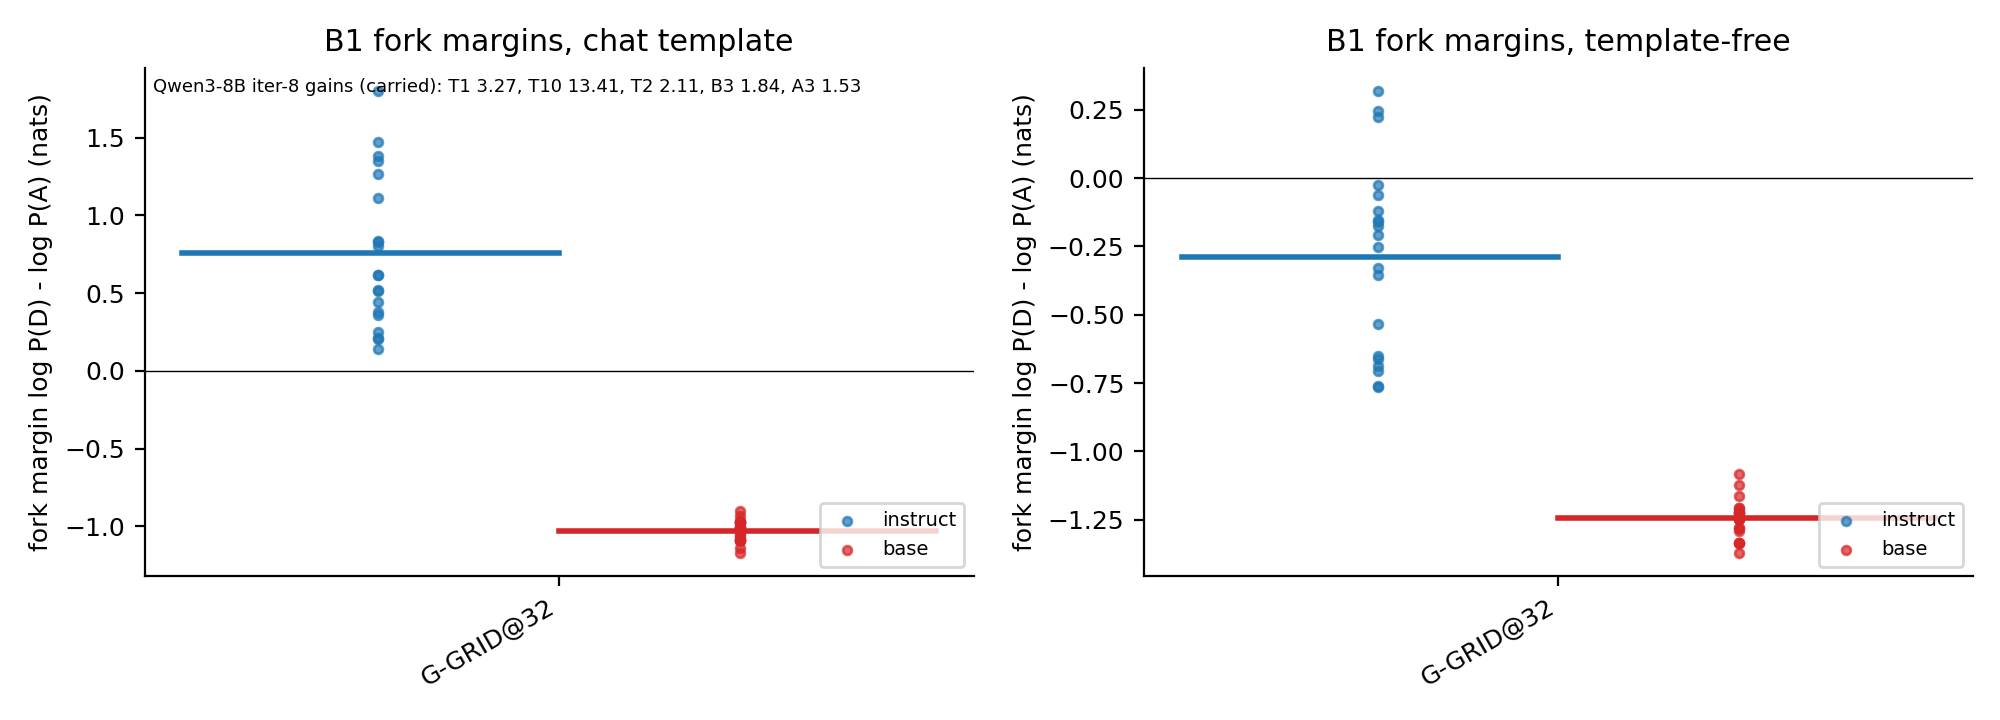

F2_b1_js_controls.png


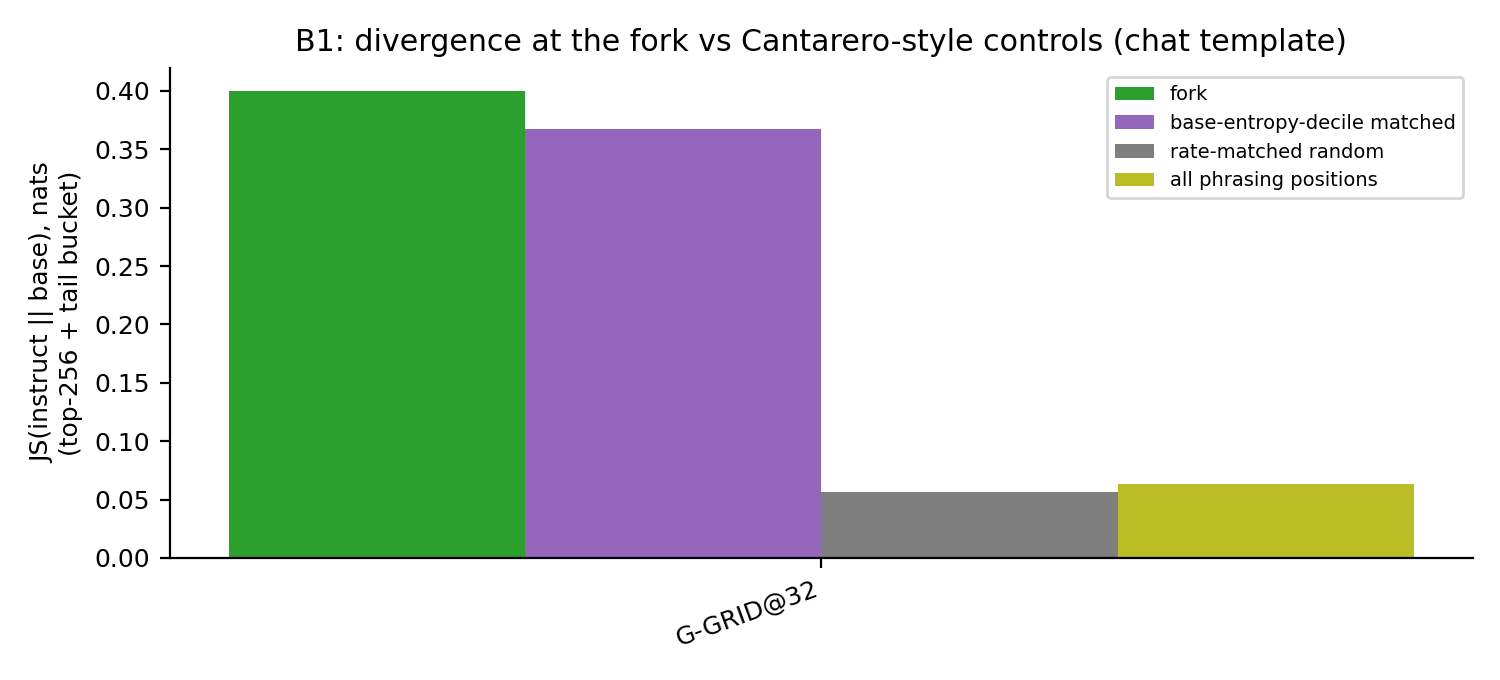

F3_b2_singles_by_layer.png


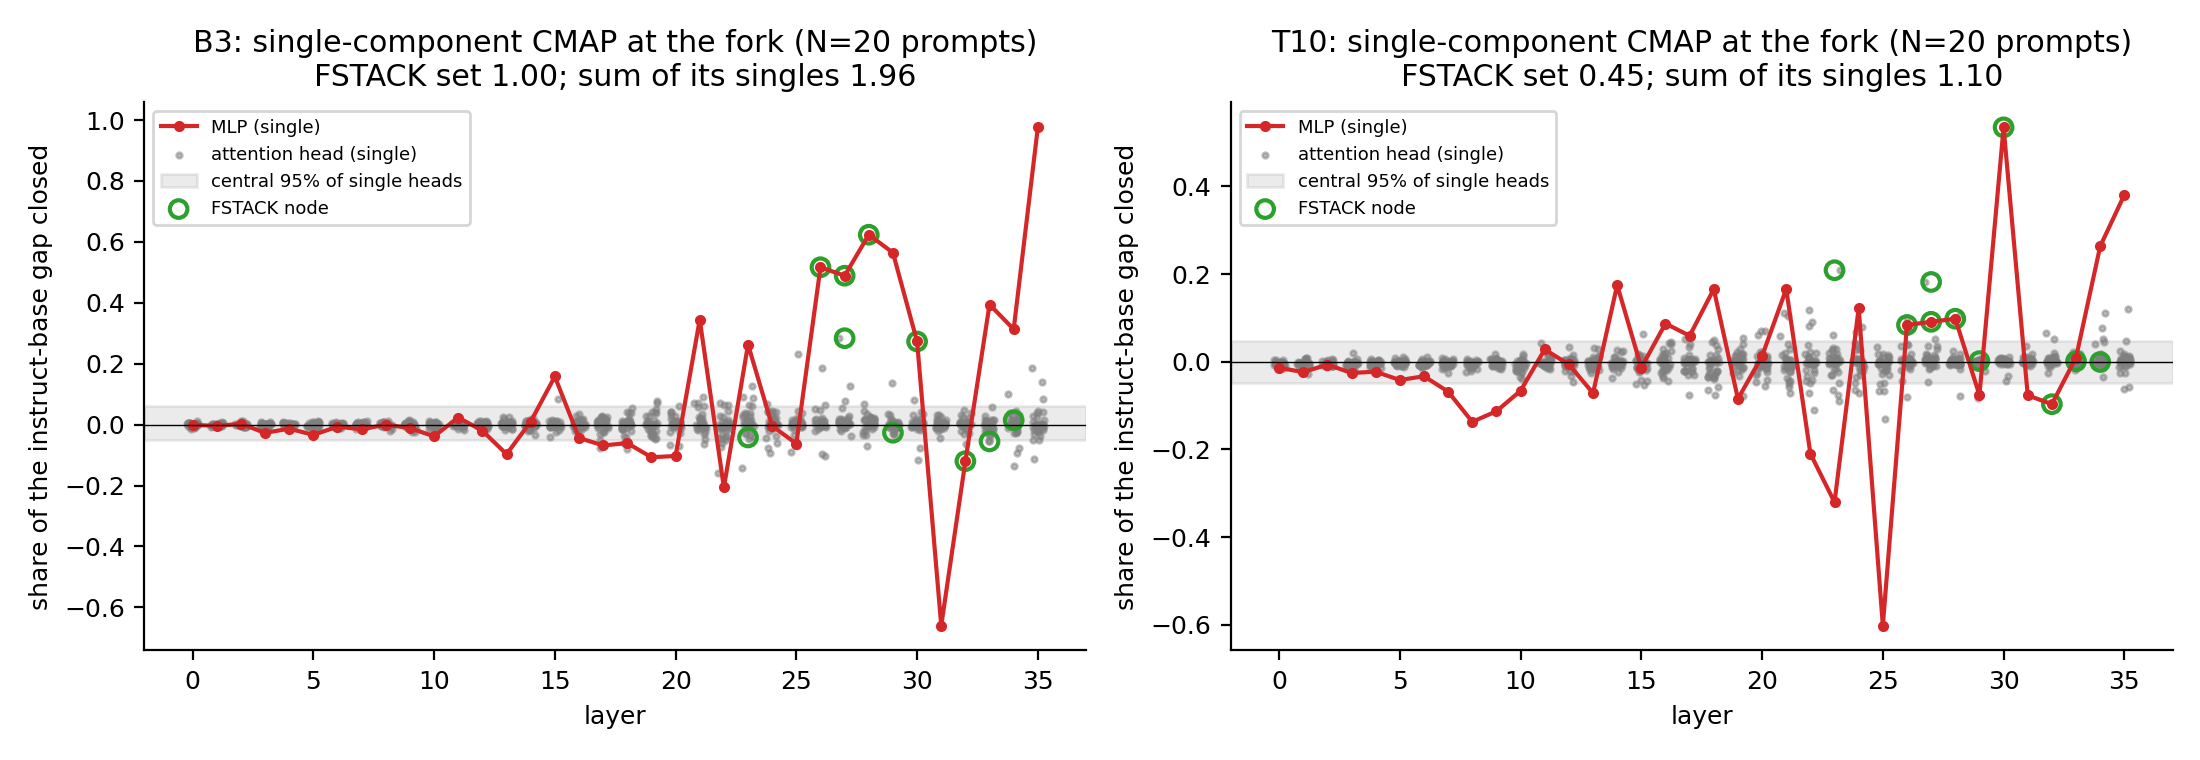

F4_b2_residual_swaps.png


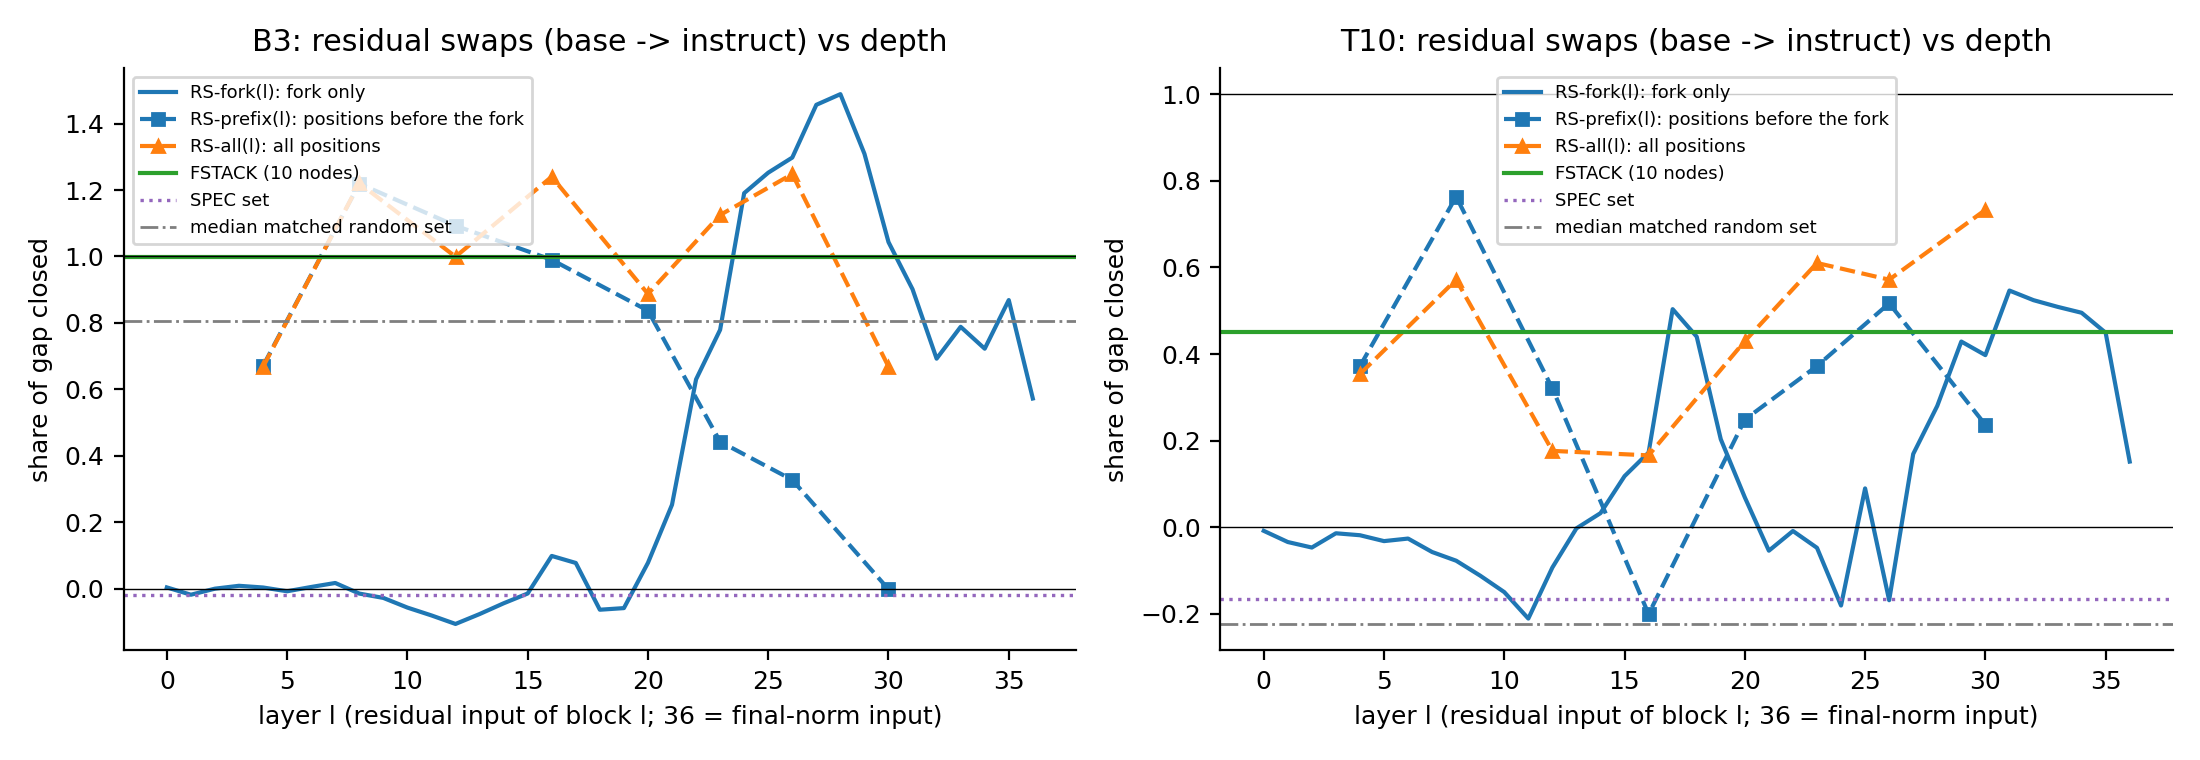

F5_b2_random_null.png


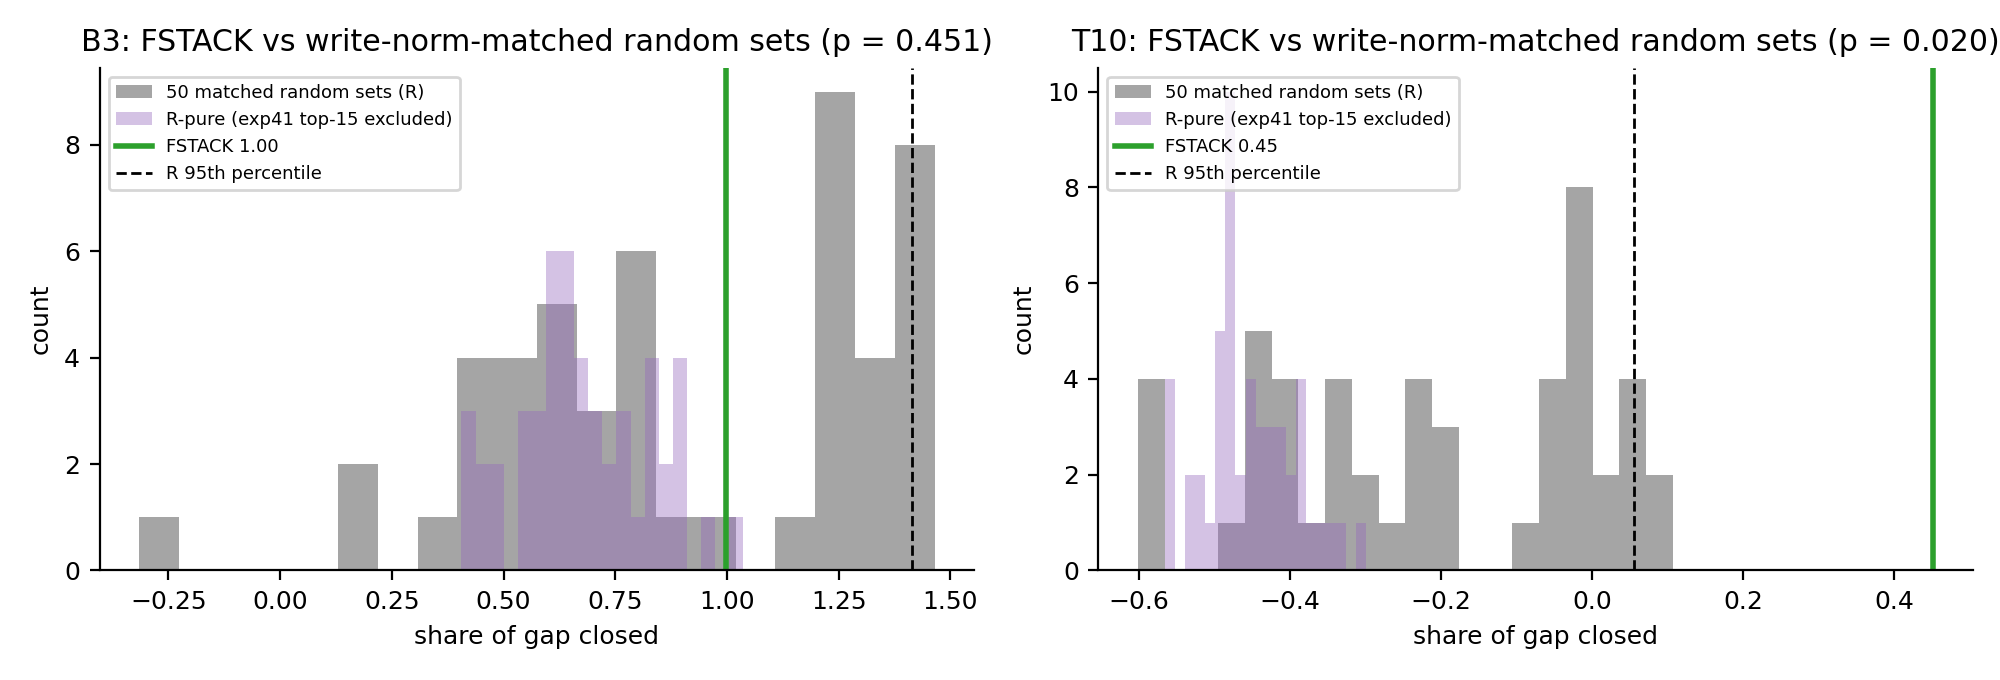

F6_b2_generation.png


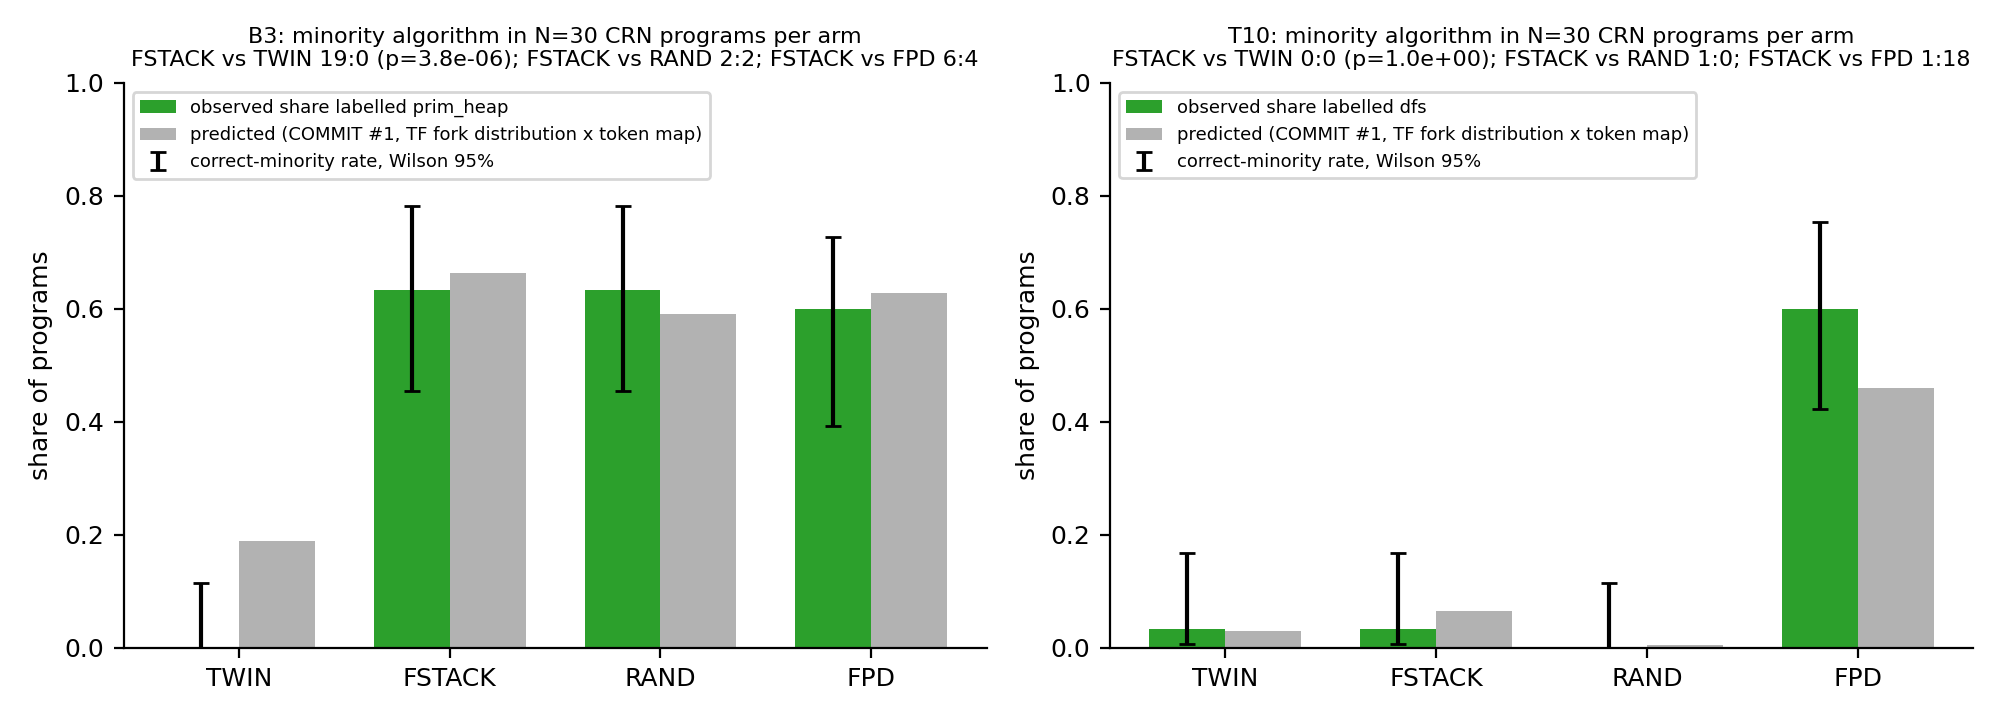

F7_b3_heldout.png


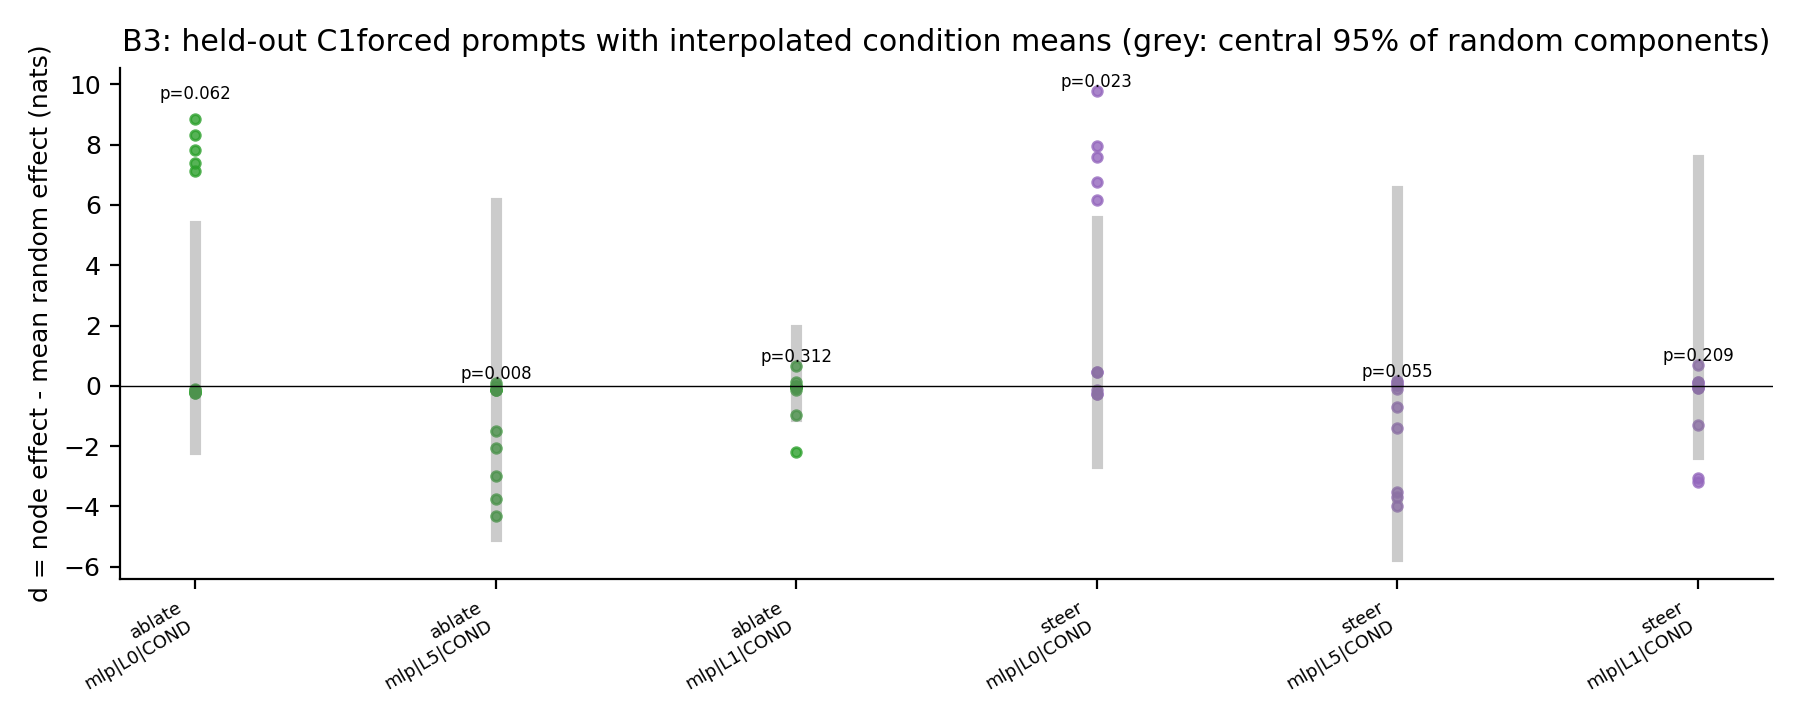

In [23]:
METHOD.main(["--stages", "figures"])
for p in sorted(FIG_DIR.glob("*.png")):
    print(p.name)
    display(Image(filename=str(p), width=880))

## Stage `rederive`: independent re-derivation with placebos (`src/rederive9.py`)

This script uses only the Python standard library: no numpy and no project imports. It recomputes every headline
number from the raw per-prompt rows and compares it with the summaries written above (tolerance 1e-6):

* B2 shares and random-null statistics; B1 gains; B3 mean effects and exact sign-flip p-values; the generation
  McNemar counts;
* the commitment chain, and whether the decisive rows were written after their commit.

Each claim also gets a **placebo that must fail**: permuted node labels, swapped anchors, swapped labels,
sign-shuffled effects, shuffled CRN pairs, and arms swapped within each pair.

In [24]:
# ---------------- src/rederive9.py (standard library only)
ROOT = Path("iter9_replay").resolve()   # [notebook] was Path(__file__).resolve().parents[1]
RES = ROOT / "results"
TOL = 1e-6


def jl(p: Path) -> list[dict]:
    with open(p) as fh:
        return [json.loads(x) for x in fh if x.strip()]


def pct(xs: list[float], q: float) -> float:
    """numpy-default (linear) percentile."""
    s = sorted(xs)
    k = (len(s) - 1) * q / 100
    f = int(k)
    c = min(f + 1, len(s) - 1)
    return s[f] + (s[c] - s[f]) * (k - f)


def b2(mism: list, out: dict) -> None:
    summ = json.loads((RES / "b2_summary.json").read_text())
    for u in ("B3", "T10"):
        rows = jl(RES / f"b2_tf_{u}.jsonl")
        mI, mB, arm = {}, {}, {}
        for r in rows:
            mI[r["pid"]] = r["m_I"]
            mB[r["pid"]] = r["m_B"]
            arm.setdefault(r["arm"], {})[r["pid"]] = r["m"]
        pids = sorted(mI)
        den = sum(mI[p] - mB[p] for p in pids)

        def sh(a: str) -> float:
            return sum(mI[p] - arm[a][p] for p in pids) / den
        rec = {"FSTACK": sh("FSTACK"), "RSfork36": sh("RSfork36"), "RSfork23": sh("RSfork23"),
               "SPEC": sh("SPEC") if "SPEC" in arm else None, "gap_mean": statistics.mean(mI[p] - mB[p] for p in pids)}
        R = [sh(f"R{s}") for s in range(50)]
        rec["R_median"] = statistics.median(R)
        rec["R_p95"] = pct(R, 95)
        rec["R_empirical_p"] = (1 + sum(x >= rec["FSTACK"] for x in R)) / 51
        S = summ["units"][u]
        cmp_ = {"FSTACK": S["arms"]["FSTACK"]["share"], "RSfork36": S["RS_fork"]["36"],
                "RSfork23": S["RS_fork"]["23"], "SPEC": S["arms"].get("SPEC", {}).get("share"),
                "gap_mean": S["gap_mean"], "R_median": S["null_R"]["median"], "R_p95": S["null_R"]["p95"],
                "R_empirical_p": S["null_R"]["empirical_p_upper"]}
        for k, v in rec.items():
            if v is None or cmp_.get(k) is None:
                continue
            if abs(v - cmp_[k]) > TOL:
                mism.append(f"B2 {u} {k}: rederived {v} vs summary {cmp_[k]}")
        # placebo: node-label permutation -> treat a random R set as 'the circuit' against the other 49 sets
        rng = random.Random(7)
        ps = []
        for _ in range(200):
            j = rng.randrange(50)
            others = [x for i, x in enumerate(R) if i != j]
            ps.append((1 + sum(x >= R[j] for x in others)) / 50)
        rec["placebo_permuted_node_labels_frac_p_le_0.05"] = sum(p <= 0.05 for p in ps) / len(ps)
        rec["placebo_permuted_node_labels_fails"] = rec["placebo_permuted_node_labels_frac_p_le_0.05"] <= 0.10
        # placebo: swap the instruct and base anchors -> FSTACK 'share' sign flips relative to the gap
        rec["placebo_anchor_swap_share"] = sum(mB[p] - arm["FSTACK"][p] for p in pids) / sum(mB[p] - mI[p]
                                                                                             for p in pids)
        out[f"B2_{u}"] = rec


def b1(mism: list, out: dict) -> None:
    summ = json.loads((RES / "b1_summary.json").read_text())
    pairs = {"gemma": ("gemma", "gemma_pt"), "llama": ("llama", "llama_base")}
    for fam, (ki, kb) in pairs.items():
        pi, pb = RES / f"b1_tf_{ki}.json", RES / f"b1_tf_{kb}.json"
        if not (pi.exists() and pb.exists()):
            continue
        I, B = json.loads(pi.read_text()), json.loads(pb.read_text())
        units = json.loads((RES / "units.json").read_text())
        for u, ru in I["units"].items():
            U = units[u]
            byI = {r["pid"]: r for r in ru["prompts"]}
            byB = {r["pid"]: r for r in B["units"][u]["prompts"]}
            keep = [p["pid"] for p in U["prompts"]
                    if min(byI[p["pid"]]["forks"][f["fork_id"]]["chat"]["logp_opening"] for f in U["forks"]) >= -5.0]
            keep = keep[:U.get("max_prompts", 20)]
            if not keep:                       # committed rule drops every prompt -> descriptive on all prompts
                keep = [p["pid"] for p in U["prompts"]][:U.get("max_prompts", 20)]
                out[f"B1_{u}_descriptive_only"] = True
            for f in U["forks"]:
                fid = f["fork_id"]
                for mode in ("chat", "plain"):
                    g = [byI[k]["forks"][fid][mode]["margin"] - byB[k]["forks"][fid][mode]["margin"] for k in keep]
                    gm = statistics.mean(g)
                    ref = summ["units"][u]["forks"][fid][mode]["gain_mean"]
                    if abs(gm - ref) > TOL:
                        mism.append(f"B1 {fid} {mode} gain: rederived {gm} vs summary {ref}")
                    out[f"B1_{fid}_{mode}_gain"] = gm
                    # placebo: swapped labels -> the >= 2 nat gain criterion must fail
                    out[f"B1_{fid}_{mode}_placebo_swapped_gain"] = -gm
                    out[f"B1_{fid}_{mode}_placebo_fails"] = (-gm) < 2.0


def b3(mism: list, out: dict) -> None:
    p = RES / "b3_heldout_rows.jsonl"
    if not p.exists():
        return
    rows = jl(p)
    summ = json.loads((RES / "b3_summary.json").read_text())
    for key, v in summ["per_node"].items():
        if not key.startswith("aligned|") or v["mode"] not in ("ablate", "steer"):
            continue
        d = []
        for r in rows:
            node = r["res"].get(f"{key}|node")
            rv = [r["res"][f"{key}|r{j}"] for j in range(50) if f"{key}|r{j}" in r["res"]]
            if node is None or not rv:
                continue
            d.append(node - sum(rv) / len(rv))
        md = statistics.mean(d)
        if abs(md - v["mean_d_heldout"]) > TOL:
            mism.append(f"B3 {key} mean_d: rederived {md} vs summary {v['mean_d_heldout']}")
        obs = abs(md)
        cnt = sum(1 for s in itertools.product((1, -1), repeat=len(d))
                  if abs(sum(a * b for a, b in zip(d, s)) / len(d)) >= obs - 1e-12)
        pv = cnt / 2 ** len(d)
        if abs(pv - v["p_sign_flip_heldout"]) > TOL:
            mism.append(f"B3 {key} p: rederived {pv} vs summary {v['p_sign_flip_heldout']}")
        # placebo: random sign assignment of the per-prompt d (shuffled pairing) -> p should usually be large
        rng = random.Random(11)
        pl = []
        for _ in range(100):
            dd = [x * rng.choice((1, -1)) for x in d]
            o2 = abs(statistics.mean(dd))
            c2 = sum(1 for s in itertools.product((1, -1), repeat=len(dd))
                     if abs(sum(a * b for a, b in zip(dd, s)) / len(dd)) >= o2 - 1e-12)
            pl.append(c2 / 2 ** len(dd))
        out[f"B3_{key}"] = {"mean_d": md, "p": pv, "placebo_sign_shuffle_frac_p_le_0.05":
                            sum(x <= 0.05 for x in pl) / len(pl)}


def gen(mism: list, out: dict) -> None:
    raw = jl(RES.parent / "data" / "samples.jsonl")
    lab = {r["sid"]: r for r in jl(RES.parent / "data" / "labels_gen.jsonl")}
    summ = json.loads((RES / "b2_generation.json").read_text())
    minority = {"B3": {"prim_heap", "prim_array"}, "T10": {"dfs", "bfs"}}
    for u in ("B3", "T10"):
        ind = {}
        for r in raw:
            if r["task"] != u:
                continue
            L = lab[r["sid"]]
            ind.setdefault(r["arm"], {})[(r["template"], r["slot"])] = int(L["label"] in minority[u] and L["passed"])
        for a, b in (("FSTACK", "TWIN"), ("FSTACK", "RAND"), ("FSTACK", "FPD"), ("FPD", "TWIN")):
            ks = sorted(set(ind[a]) & set(ind[b]))
            n10 = sum(1 for k in ks if ind[a][k] == 1 and ind[b][k] == 0)
            n01 = sum(1 for k in ks if ind[a][k] == 0 and ind[b][k] == 1)
            ref = summ[u]["tests"][f"{a}_vs_{b}"]
            if (n10, n01) != (ref["b_first_only"], ref["c_second_only"]):
                mism.append(f"gen {u} {a}_vs_{b}: rederived {n10}:{n01} vs {ref['b_first_only']}:{ref['c_second_only']}")
            n = n10 + n01
            p = min(1.0, 2 * sum(__import__("math").comb(n, i) for i in range(0, min(n10, n01) + 1)) / 2 ** n) if n else 1.0
            out[f"gen_{u}_{a}_vs_{b}"] = {"b": n10, "c": n01, "p": p}
            # placebo: shuffle the CRN slot pairing of the second arm -> the paired McNemar should lose significance
            rng = random.Random(5)
            pl = []
            for _ in range(200):
                kk = ks[:]
                rng.shuffle(kk)
                m10 = sum(1 for k, k2 in zip(ks, kk) if ind[a][k] == 1 and ind[b][k2] == 0)
                m01 = sum(1 for k, k2 in zip(ks, kk) if ind[a][k] == 0 and ind[b][k2] == 1)
                nn = m10 + m01
                pl.append(min(1.0, 2 * sum(__import__("math").comb(nn, i) for i in range(0, min(m10, m01) + 1))
                              / 2 ** nn) if nn else 1.0)
            out[f"gen_{u}_{a}_vs_{b}"]["placebo_slot_shuffle_median_p"] = statistics.median(pl)
            out[f"gen_{u}_{a}_vs_{b}"]["note_slot_shuffle"] = ("uninformative when one arm has no minority programs "
                                                              "(the contrast is then marginal, pairing-free)")
            # placebo 2: swap the two arms' labels within each CRN pair at random (the null McNemar permutes)
            pl2 = []
            for _ in range(200):
                m10 = m01 = 0
                for k in ks:
                    x, y = (ind[a][k], ind[b][k]) if rng.random() < 0.5 else (ind[b][k], ind[a][k])
                    m10 += int(x == 1 and y == 0)
                    m01 += int(x == 0 and y == 1)
                nn = m10 + m01
                pl2.append(min(1.0, 2 * sum(__import__("math").comb(nn, i) for i in range(0, min(m10, m01) + 1))
                               / 2 ** nn) if nn else 1.0)
            out[f"gen_{u}_{a}_vs_{b}"]["placebo_within_pair_arm_swap_median_p"] = statistics.median(pl2)
            out[f"gen_{u}_{a}_vs_{b}"]["placebo_within_pair_arm_swap_frac_p_le_0.05"] = sum(x <= 0.05 for x in pl2) / 200


def chain(mism: list, out: dict) -> None:
    """Commit chain links (sha256(prev + file sha)) and 'decisive rows after their commit' (stdlib)."""
    import hashlib
    lines = [l.split() for l in (ROOT / "commitments.log").read_text().splitlines() if l.strip()]
    prev = hashlib.sha256(b"iter9_base").hexdigest()
    ok = True
    when = {}
    for utc, name, fsha, link in lines:
        fs = hashlib.sha256((ROOT / "predictions" / f"{name}.json").read_bytes()).hexdigest()
        ok &= fs == fsha and hashlib.sha256((prev + fsha).encode()).hexdigest() == link
        prev = link
        when[name] = utc
    first = {}
    for nm, path in (("b2_tf", RES / "b2_tf_B3.jsonl"), ("b3_heldout", RES / "b3_heldout_rows.jsonl"),
                     ("generation", RES.parent / "data" / "samples.jsonl")):
        rows = jl(path)
        first[nm] = min(r["utc"] for r in rows) if rows else None
    order = {"b2_tf_after_commit0": first["b2_tf"] > when.get("commit0", "~"),
             "b3_heldout_after_commitB3": first["b3_heldout"] > when.get("commitB3", "~"),
             "generation_after_commit1_gen": first["generation"] > when.get("commit1_gen", "~")}
    out["commit_chain"] = {"n": len(lines), "all_ok": ok, "commits": when, "first_rows": first, "order": order}
    if not ok:
        mism.append("commit chain does not verify")
    for k, v in order.items():
        if not v:
            mism.append(f"timestamp order fails: {k}")


def main() -> None:
    mism: list[str] = []
    out: dict = {}
    for fn in (b2, b1, b3, gen, chain):
        try:
            fn(mism, out)
        except FileNotFoundError as e:
            out[f"{fn.__name__}_missing"] = str(e)
    out["mismatches"] = mism
    out["n_mismatches"] = len(mism)
    (RES / "rederive.json").write_text(json.dumps(out, indent=1))
    print(f"rederive: {len(mism)} mismatches")
    for m in mism[:20]:
        print("  ", m)


RED = SimpleNamespace(main=main)   # [notebook] rederive9 namespace

In [25]:
METHOD.main(["--stages", "rederive"])
rd = json.loads((RESULTS_DIR / "rederive.json").read_text())
print(f"mismatches between the stdlib re-derivation and the summaries: {rd['n_mismatches']}", rd["mismatches"][:5])
for u in ("B3", "T10"):
    r_ = rd[f"B2_{u}"]
    print(f"  B2 {u}: FSTACK {r_['FSTACK']:.3f}, R median {r_['R_median']:.3f}, p {r_['R_empirical_p']:.3f} | placebo "
          f"(a random set as 'the circuit'): {100 * r_['placebo_permuted_node_labels_frac_p_le_0.05']:.0f}% of draws "
          f"p <= 0.05 -> fails as required: {r_['placebo_permuted_node_labels_fails']}")
for k, v in rd.items():
    if k.startswith("B1_") and k.endswith("_placebo_fails"):
        print(f"  {k}: {v}")
    if k.startswith("B3_aligned"):
        print(f"  {k}: mean d {v['mean_d']:.3f}, p {v['p']:.4f}, sign-shuffle placebo p <= 0.05 in "
              f"{100 * v['placebo_sign_shuffle_frac_p_le_0.05']:.0f}% of draws")
    if k.startswith("gen_"):
        print(f"  {k}: {v['b']}:{v['c']} p = {v['p']:.2g}; within-pair arm-swap placebo median p "
              f"{v['placebo_within_pair_arm_swap_median_p']:.2f}")
print("  commit chain:", rd["commit_chain"]["all_ok"], "| decisive rows after their commit:", rd["commit_chain"]["order"])

20:01:35|INFO   |stage rederive: rederive9.py


rederive: 0 mismatches
20:01:36|INFO   |stage rederive: done in 1s


mismatches between the stdlib re-derivation and the summaries: 0 []
  B2 B3: FSTACK 0.998, R median 0.807, p 0.451 | placebo (a random set as 'the circuit'): 3% of draws p <= 0.05 -> fails as required: True
  B2 T10: FSTACK 0.452, R median -0.223, p 0.020 | placebo (a random set as 'the circuit'): 6% of draws p <= 0.05 -> fails as required: True
  B1_G-GRID@32_chat_placebo_fails: True
  B1_G-GRID@32_plain_placebo_fails: True
  B3_aligned|ablate|mlp|L0|H-1|COND: mean d 3.857, p 0.0625, sign-shuffle placebo p <= 0.05 in 3% of draws
  B3_aligned|ablate|mlp|L5|H-1|COND: mean d -1.499, p 0.0078, sign-shuffle placebo p <= 0.05 in 1% of draws
  B3_aligned|ablate|mlp|L1|H-1|COND: mean d -0.268, p 0.3125, sign-shuffle placebo p <= 0.05 in 5% of draws
  B3_aligned|steer|mlp|L0|H-1|COND: mean d 3.850, p 0.0234, sign-shuffle placebo p <= 0.05 in 1% of draws
  B3_aligned|steer|mlp|L5|H-1|COND: mean d -1.308, p 0.0547, sign-shuffle placebo p <= 0.05 in 3% of draws
  B3_aligned|steer|mlp|L1|H-1|COND:

## Results: the replay against the recorded run, and the fork in activation space

**The check table** compares the headline numbers computed above with the ones the original run recorded, which are
bundled under `reference` in `mini_demo_data.json`. At the original configuration every row should match. At a reduced
configuration, rows that depend on fewer prompts, programs or resamples differ.

**The geometry view** uses actual activation vectors: the input of block 31 (the block-30 output) of Qwen3-8B at the
fork, as captured by the patching stage. For each prompt it shows four states:

* the unpatched instruct state;
* FSTACK-patched (the base model's outputs of the 10 fork-stack nodes written in);
* patched with the median matched random set;
* RS-fork(23), where the base model's residual stream at layer 23 is swapped in.

The PCA is fit on the instruct and FSTACK-patched states. The paper's F8 fits on instruct and base states, which are
not published. Colour is the fork margin each state produces. The bottom row plots each state's PC1 coordinate
against its margin; the dashed line is the base model's mean margin.

One caveat when reading it: components above layer 30 act after this capture point. These are FSTACK's MLP L32 and
heads L33 H14 and L34 H28, plus any layer 31-35 members of a random set. Their effect on the margin does not show in
these states. That is why, on MST, the median random set gets close to the base model's margin while moving only
about a third of the way along PC1.

quantity                                                           replayed                   recorded  match
B2 B3 gap m_I - m_B                                                   2.059                      2.059  yes
B2 B3 FSTACK share                                                    0.998                      0.998  yes
B2 B3 FSTACK share 95% CI                                    [0.958, 1.040]             [0.958, 1.040]  yes
B2 B3 random sets: median                                             0.807                      0.807  yes
B2 B3 random sets: p of FSTACK                                        0.451                      0.451  yes
B2 B3 SPEC share                                                     -0.019                     -0.019  yes
B2 B3 RS-fork(36)                                                     0.573                      0.573  yes
B2 B3 REV share opened                                               -0.304                     -0.304  yes
B2 B3 localisation        

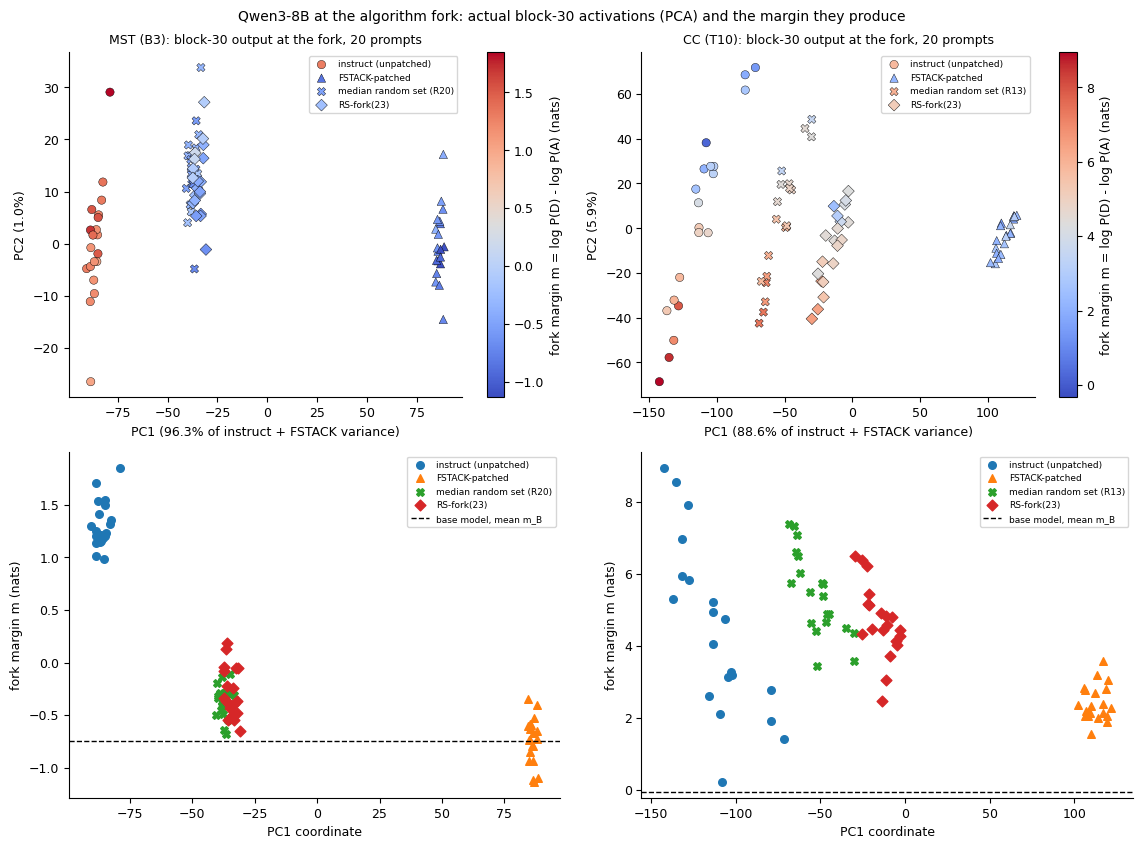

In [26]:
ref = data["reference"]
b1s, b2s, b3s = (read_json(RESULTS_DIR / f"{n}.json") for n in ("b1_summary", "b2_summary", "b3_summary"))
gres, rd = read_json(RESULTS_DIR / "b2_generation.json"), json.loads((RESULTS_DIR / "rederive.json").read_text())
checks = []


def nb_check(name, got, want):
    """[notebook] one row of the check table: replayed value vs recorded value (relative tolerance 1e-9)."""
    num = lambda x: isinstance(x, (int, float)) and not isinstance(x, bool)
    if num(want) and num(got):
        ok = abs(got - want) <= 1e-9 * max(1.0, abs(want))
    elif isinstance(want, list) and isinstance(got, list):
        ok = len(got) == len(want) and all(abs(a - b) <= 1e-9 * max(1.0, abs(b)) for a, b in zip(got, want))
    else:
        ok = got == want
    checks.append((name, got, want, ok))


for u in ("B3", "T10"):
    s, r = b2s["units"][u], ref["b2"][u]
    nb_check(f"B2 {u} gap m_I - m_B", s["gap_mean"], r["gap_mean"])
    nb_check(f"B2 {u} FSTACK share", s["arms"]["FSTACK"]["share"], r["FSTACK"])
    nb_check(f"B2 {u} FSTACK share 95% CI", s["arms"]["FSTACK"]["share_ci95"], r["FSTACK_ci95"])
    nb_check(f"B2 {u} random sets: median", s["null_R"]["median"], r["R_median"])
    nb_check(f"B2 {u} random sets: p of FSTACK", s["null_R"]["empirical_p_upper"], r["R_p"])
    nb_check(f"B2 {u} SPEC share", s["arms"]["SPEC"]["share"], r["SPEC"])
    nb_check(f"B2 {u} RS-fork(36)", s["RS_fork"]["36"], r["RSfork36"])
    nb_check(f"B2 {u} REV share opened", s["REV"]["share_opened_FSTACK"], r["REV_FSTACK"])
    nb_check(f"B2 {u} localisation", s["localisation"], r["localisation"])
nb_check("B2 verdict", b2s["verdict"], ref["b2"]["verdict"])
fr, r1 = b1s["units"]["G-GRID"]["forks"]["G-GRID@32"], ref["b1"]
nb_check("B1 G-GRID@32 chat gain", fr["chat"]["gain_mean"], r1["chat_gain_mean"])
nb_check("B1 G-GRID@32 chat gain 95% CI", fr["chat"]["gain_ci95"], r1["chat_gain_ci95"])
nb_check("B1 G-GRID@32 template-free gain", fr["plain"]["gain_mean"], r1["plain_gain_mean"])
nb_check("B1 G-GRID@32 phrasing dH", fr["phrasing"]["dH_mean"], r1["dH_mean"])
nb_check("B1 G-GRID@32 JS fork / matched", fr["phrasing"]["ratio_fork_vs_matched"], r1["ratio_fork_vs_matched"])
nb_check("B1 G-GRID@32 Cantarero in / out", fr["cantarero"]["ratio_inside_outside"],
         r1["cantarero_ratio_inside_outside"])
for k, v in ref["b3"].items():
    nb_check(f"B3 {k.split('|', 2)[1]} {k.split('|', 2)[2].replace('|H-1|COND', '')} mean d",
             b3s["per_node"][k]["mean_d_heldout"], v["mean_d_heldout"])
    nb_check(f"B3 {k.split('|', 2)[1]} {k.split('|', 2)[2].replace('|H-1|COND', '')} p sign-flip",
             b3s["per_node"][k]["p_sign_flip_heldout"], v["p_sign_flip_heldout"])
for u in ("B3", "T10"):
    nb_check(f"gen {u} correct minority TWIN/FSTACK/RAND/FPD",
             [gres[u]["cells"][a]["n_correct_minority"] for a in ARMS], [ref["gen"][u]["n_correct_minority"][a]
                                                                          for a in ARMS])
    for t in ("FSTACK_vs_TWIN", "FSTACK_vs_RAND", "FPD_vs_TWIN"):
        v = gres[u]["tests"][t]
        nb_check(f"gen {u} McNemar {t} (b, c, p)", [v["b_first_only"], v["c_second_only"], v["p_exact_two_sided"]],
                 ref["gen"][u]["tests"][t])
nb_check("rederive mismatches", rd["n_mismatches"], ref["rederive_n_mismatches"])
print(f"{'quantity':48s} {'replayed':>26s} {'recorded':>26s}  match")
for name, got, want, ok in checks:
    print(f"{name:48s} {nb_f(got):>26s} {nb_f(want):>26s}  {'yes' if ok else 'NO'}")
print(f"\n{sum(c[3] for c in checks)} of {len(checks)} replayed values equal the recorded ones "
      f"(config: N_BOOT={N_BOOT}, MAX_PROMPTS={MAX_PROMPTS}, B1_PROGRAMS={B1_PROGRAMS}, GEN_SLOTS={GEN_SLOTS}, "
      f"B3_HELDOUT={B3_HELDOUT})")


def nb_bf16(b64_list):
    """[notebook] base64 bf16 vectors -> float32 array [n, 4096] (a bf16 value is the top half of a float32)."""
    u16 = np.stack([np.frombuffer(base64.b64decode(s_), dtype="<u2") for s_ in b64_list])
    return (u16.astype(np.uint32) << 16).view(np.float32)


fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.6))
for col, u in enumerate(("B3", "T10")):
    geo, t = rec["geometry"][u], rec["b2_tf"][u]
    P = min(MAX_PROMPTS, len(geo["pids"]))
    med = geo["median_random_set"]
    kinds = {"instruct (unpatched)": ("none", "o"), "FSTACK-patched": ("FSTACK", "^"),
             f"median random set (R{med})": (f"R{med}", "X"), "RS-fork(23)": ("RSfork23", "D")}
    X = {lab_: nb_bf16(geo["states"][k][:P]) for lab_, (k, _) in kinds.items()}
    M = {lab_: np.asarray(t["arms"][k][:P]) for lab_, (k, _) in kinds.items()}
    fit = np.concatenate([X["instruct (unpatched)"], X["FSTACK-patched"]])
    mu = fit.mean(0)
    _, Sv, Vt = np.linalg.svd(fit - mu, full_matrices=False)
    ev = Sv ** 2 / (Sv ** 2).sum()
    mB = np.asarray(t["m_B"][:P])
    allm = np.concatenate(list(M.values()) + [mB])
    Y = {lab_: (X[lab_] - mu) @ Vt[:2].T for lab_ in kinds}
    for lab_, (k, mk) in kinds.items():
        sc = axes[0, col].scatter(Y[lab_][:, 0], Y[lab_][:, 1], c=M[lab_], cmap="coolwarm", vmin=allm.min(),
                                  vmax=allm.max(), marker=mk, s=36, edgecolors="k", linewidths=0.3, label=lab_)
        axes[1, col].scatter(Y[lab_][:, 0], M[lab_], marker=mk, s=30, label=lab_)
    fig.colorbar(sc, ax=axes[0, col], label="fork margin m = log P(D) - log P(A) (nats)")
    axes[0, col].set_xlabel(f"PC1 ({100 * ev[0]:.1f}% of instruct + FSTACK variance)")
    axes[0, col].set_ylabel(f"PC2 ({100 * ev[1]:.1f}%)")
    axes[0, col].set_title(f"{U2[u]}: block-30 output at the fork, {P} prompts", fontsize=9)
    axes[0, col].legend(fontsize=6.5)
    axes[1, col].axhline(mB.mean(), color="k", ls="--", lw=1, label="base model, mean m_B")
    axes[1, col].set_xlabel("PC1 coordinate")
    axes[1, col].set_ylabel("fork margin m (nats)")
    axes[1, col].legend(fontsize=6.5)
    dx = Y["FSTACK-patched"][:, 0] - Y["instruct (unpatched)"][:, 0]
    frac = {lab_: float(np.mean((Y[lab_][:, 0] - Y["instruct (unpatched)"][:, 0]) / dx)) for lab_ in list(kinds)[2:]}
    d_ = X["FSTACK-patched"] - X["instruct (unpatched)"]
    cos = (d_ @ d_.T) / np.outer(np.linalg.norm(d_, axis=1), np.linalg.norm(d_, axis=1))
    print(f"{U2[u]}: PC1 holds {100 * ev[0]:.1f}% of the instruct + FSTACK variance; along PC1 the median random set "
          f"moves {frac[list(kinds)[2]]:.2f} and RS-fork(23) {frac['RS-fork(23)']:.2f} of the FSTACK displacement; "
          f"mean cosine between prompts' FSTACK displacements {cos[np.triu_indices(P, 1)].mean():.2f}")
fig.suptitle("Qwen3-8B at the algorithm fork: actual block-30 activations (PCA) and the margin they produce", fontsize=10)
fig.tight_layout()
plt.show()